# UNISOLAR Dataset Exploration

## Project
Solar Power Forecasting using Hybrid XGBoost-LSTM

## Dataset
UNISOLAR Solar Power Generation Dataset

## Mục tiêu
Notebook này thực hiện phân tích dữ liệu khám phá (EDA) trên bộ dữ liệu UNISOLAR
nhằm phục vụ việc dự báo ngắn hạn sản lượng điện mặt trời.


## 1. Import thư viện

In [2]:
import os, glob, warnings, json, platform, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
pd.set_option('display.max_columns', None)
DATA_ROOT = Path('/kaggle/input')
OUTPUT_DIR = Path("/kaggle/working/experiment_D")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Đây là tái dựng NGOẠI TUYẾN: GHI nội suy theo bài báo dùng cả hai đầu mút.
# Chưa phải thí nghiệm dự báo trước h bước với mọi covariate khả dụng tại thời điểm phát.
# Bật để chạy đầy đủ các biến thể Hybrid; không thay bằng XGBoost-only.
RUN_FULL_ABLATION = True
print('DATA_ROOT:', DATA_ROOT)
print('OUTPUT_DIR:', OUTPUT_DIR)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

DATA_ROOT: /kaggle/input
OUTPUT_DIR: /kaggle/working/experiment_D
TensorFlow: 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load file

In [3]:
def find_file(filename):
    matches = sorted(set(DATA_ROOT.rglob(filename)) | set(DATA_ROOT.rglob(filename+'.zip')))
    matches = [p for p in matches if p.is_file() and OUTPUT_DIR not in p.parents]
    if len(matches) != 1:
        raise FileNotFoundError(f'Cần đúng 1 file {filename} hoặc {filename}.zip trong {DATA_ROOT}; tìm thấy: {matches}. Hãy đổi DATA_ROOT hoặc giữ một bản dữ liệu.')
    print(filename, '->', matches[0])
    return matches[0]
solar_path = find_file('Solar_Energy_Generation.csv')
site_path = find_file('Solar_Site_Details.csv')
monthly_path = find_file('Monthly_Summary_Solar.csv')
irradiance_path = find_file('Solar_Irradiance.csv')

Solar_Energy_Generation.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Solar_Energy_Generation.csv
Solar_Site_Details.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Solar_Site_Details.csv
Monthly_Summary_Solar.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Monthly_Summary_Solar.csv
Solar_Irradiance.csv -> /kaggle/input/datasets/maiemm/solar-irradiance/Solar_Irradiance.csv


In [4]:
weather_path = find_file('Weather_Data_reordered_all.csv')

Weather_Data_reordered_all.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Weather_Data_reordered_all.csv


## 3. Đọc dữ liệu

In [5]:
import zipfile, hashlib

def read_csv_input(path):
    if str(path).lower().endswith('.zip'):
        with zipfile.ZipFile(path) as z:
            names=[s for s in z.namelist() if s.lower().endswith('.csv') and not s.startswith('__MACOSX/')]
            if len(names)!=1:
                raise ValueError(f'{path} chứa {len(names)} CSV; cần chọn rõ file cần đọc.')
            with z.open(names[0]) as f:
                return pd.read_csv(f)
    return pd.read_csv(path)

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

input_paths=dict(solar=solar_path,weather=weather_path,site=site_path,monthly=monthly_path,irradiance=irradiance_path)
provenance={k:{'file':str(p),'sha256':sha256_file(p)} for k,p in input_paths.items()}
solar=read_csv_input(solar_path)
weather=read_csv_input(weather_path)
site=read_csv_input(site_path)
monthly=read_csv_input(monthly_path)
irradiance=read_csv_input(irradiance_path)

In [6]:
print("Solar:", solar.shape)
print("Weather:", weather.shape)
print("Site:", site.shape)
print("Monthly:", monthly.shape)
print("Irradiance:", irradiance.shape)

Solar: (2731946, 4)
Weather: (371769, 8)
Site: (42, 10)
Monthly: (1176, 7)
Irradiance: (102360, 4)


## 4. Xem cấu trúc dữ liệu

In [7]:
datasets = {
    "Solar": solar,
    "Weather": weather,
    "Site": site,
    "Monthly": monthly,
    "Irradiance": irradiance
}

for name, df in datasets.items():
    print("\n========================")
    print(name)
    print("========================")
    
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())
    
    display(df.head())


Solar
Shape: (2731946, 4)
Columns:
['CampusKey', 'SiteKey', 'Timestamp', 'SolarGeneration']


,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,NaN
1,2,1,2020-01-01 00:30:00,NaN
2,2,1,2020-01-01 00:45:00,NaN
3,2,1,2020-01-01 01:00:00,NaN
4,2,1,2020-01-01 01:15:00,NaN



Weather
Shape: (371769, 8)
Columns:
['CampusKey', 'Timestamp', 'ApparentTemperature', 'AirTemperature', 'DewPointTemperature', 'RelativeHumidity', 'WindSpeed', 'WindDirection']


,CampusKey,Timestamp,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
0,1,2020-01-01 00:00:00,13.666667,13.880000,8.960000,72.400000,0.000000,188.133333
1,1,2020-01-01 00:15:00,13.206667,13.666667,9.040000,73.466667,1.200000,203.866667
2,1,2020-01-01 00:30:00,12.840000,13.553333,9.053333,74.000000,2.520000,222.800000
3,1,2020-01-01 00:45:00,12.113333,13.506667,9.100000,74.466667,5.986667,231.133333
4,1,2020-01-01 01:00:00,11.946667,13.260000,9.266667,76.533333,5.946667,247.866667



Site
Shape: (42, 10)
Columns:
['CampusKey', 'SiteKey', 'kWp', 'Number of panels', 'Panel', 'Inverter', 'Optimizers', 'Metric', 'lat', 'Lon']


,CampusKey,SiteKey,kWp,Number of panels,Panel,Inverter,Optimizers,Metric,lat,Lon
0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
1,2,2,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
2,2,3,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
3,2,4,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
4,2,5,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679



Monthly
Shape: (1176, 7)
Columns:
['SiteKey', 'Year', 'Month', 'DataStatus', 'AverageSolarGeneration', 'MaxSolarGeneration', 'MinSolarGeneration']


,SiteKey,Year,Month,DataStatus,AverageSolarGeneration,MaxSolarGeneration,MinSolarGeneration
0,1,2020,January,True,10.157125,21.778,0.101
1,2,2020,January,True,8.536875,18.553,0.100
2,3,2020,January,True,6.309834,13.322,0.103
3,4,2020,January,False,NaN,NaN,NaN
4,5,2020,January,False,NaN,NaN,NaN



Irradiance
Shape: (102360, 4)
Columns:
['CloudOpacity', 'Ghi', 'Timestamp_UTC', 'Campus']


,CloudOpacity,Ghi,Timestamp_UTC,Campus
0,15.5,823,2019-12-31 00:00:00,Bundoora
1,0.0,1063,2019-12-31 01:00:00,Bundoora
2,0.0,1090,2019-12-31 02:00:00,Bundoora
3,0.0,1049,2019-12-31 03:00:00,Bundoora
4,0.0,948,2019-12-31 04:00:00,Bundoora


## 5. Chuyển timestamp

In [8]:
#solar and weather
solar["Timestamp"] = pd.to_datetime(
    solar["Timestamp"],
    errors="coerce"
)

weather["Timestamp"] = pd.to_datetime(
    weather["Timestamp"],
    errors="coerce"
)

In [9]:
#irradiance
irradiance["Timestamp_UTC"] = pd.to_datetime(
    irradiance["Timestamp_UTC"],
    errors="coerce",
    utc=True
)
irradiance["Timestamp"] = (
    irradiance["Timestamp_UTC"]
    .dt.tz_convert("Australia/Melbourne")
    .dt.tz_localize(None)
)
irradiance[
    ["Timestamp_UTC", "Timestamp", "Ghi"]
].head()

,Timestamp_UTC,Timestamp,Ghi
0,2019-12-31 00:00:00+00:00,2019-12-31 11:00:00,823
1,2019-12-31 01:00:00+00:00,2019-12-31 12:00:00,1063
2,2019-12-31 02:00:00+00:00,2019-12-31 13:00:00,1090
3,2019-12-31 03:00:00+00:00,2019-12-31 14:00:00,1049
4,2019-12-31 04:00:00+00:00,2019-12-31 15:00:00,948


In [10]:
print("Solar dtype:")
print(solar["Timestamp"].dtype)

print("\nWeather dtype:")
print(weather["Timestamp"].dtype)

print("\nIrradiance dtype:")
print(irradiance["Timestamp_UTC"].dtype)

Solar dtype:
datetime64[ns]

Weather dtype:
datetime64[ns]

Irradiance dtype:
datetime64[ns, UTC]


In [11]:
print("NaT Solar:",
      solar["Timestamp"].isna().sum())

print("NaT Weather:",
      weather["Timestamp"].isna().sum())

print("NaT Irradiance:",
      irradiance["Timestamp_UTC"].isna().sum())

NaT Solar: 0
NaT Weather: 0
NaT Irradiance: 0


## 6. Kiểm tra missing

In [12]:
def missing_summary(df):
    
    result = pd.DataFrame({
        "Missing": df.isna().sum(),
        "Missing_Percent":
            df.isna().mean() * 100
    })
    
    return result.sort_values(
        "Missing_Percent",
        ascending=False
    )


display(missing_summary(solar))
display(missing_summary(weather))
display(missing_summary(irradiance))
display(missing_summary(site))
display(missing_summary(monthly))

,Missing,Missing_Percent
SolarGeneration,1536301,56.234677
CampusKey,0,0.000000
SiteKey,0,0.000000
Timestamp,0,0.000000


,Missing,Missing_Percent
WindSpeed,162890,43.814842
WindDirection,162890,43.814842
AirTemperature,107113,28.811708
ApparentTemperature,107113,28.811708
RelativeHumidity,107113,28.811708
DewPointTemperature,107113,28.811708
CampusKey,0,0.000000
Timestamp,0,0.000000


,Missing,Missing_Percent
CloudOpacity,0,0.0
Ghi,0,0.0
Timestamp_UTC,0,0.0
Campus,0,0.0
Timestamp,0,0.0


,Missing,Missing_Percent
Optimizers,19,45.238095
kWp,17,40.476190
Inverter,17,40.476190
Metric,17,40.476190
Panel,17,40.476190
Number of panels,17,40.476190
SiteKey,0,0.000000
CampusKey,0,0.000000
lat,0,0.000000
Lon,0,0.000000


,Missing,Missing_Percent
MinSolarGeneration,200,17.006803
MaxSolarGeneration,200,17.006803
AverageSolarGeneration,200,17.006803
Month,0,0.000000
Year,0,0.000000
SiteKey,0,0.000000
DataStatus,0,0.000000


## 7. kiểm tra duplicate

In [13]:
# 1. Solar Generation
print("Solar duplicate:")
print(
    solar.duplicated(
        subset=["CampusKey", "SiteKey", "Timestamp"]
    ).sum()
)

# 2. Weather
print("Weather duplicate:")
print(
    weather.duplicated(
        subset=["CampusKey", "Timestamp"]
    ).sum()
)

# 3. Solar Site Details
print("Site duplicate:")
print(
    site.duplicated(
        subset=["CampusKey", "SiteKey"]
    ).sum()
)

# 4. Monthly Summary
print("Monthly duplicate:")
print(
    monthly.duplicated(
        subset=["SiteKey", "Year", "Month"]
    ).sum()
)

# 5. Solar Irradiance
print("Irradiance duplicate:")
print(
    irradiance.duplicated(
        subset=["Campus", "Timestamp_UTC"]
    ).sum()
)

Solar duplicate:
0
Weather duplicate:
0
Site duplicate:
0
Monthly duplicate:
0
Irradiance duplicate:
0


## 8. Chuẩn hóa SiteKey/CampusKey

In [14]:
solar["CampusKey"] = (
    solar["CampusKey"]
    .astype("int16")
)

solar["SiteKey"] = (
    solar["SiteKey"]
    .astype("int16")
)

weather["CampusKey"] = (
    weather["CampusKey"]
    .astype("int16")
)

site["CampusKey"] = (
    site["CampusKey"]
    .astype("int16")
)

site["SiteKey"] = (
    site["SiteKey"]
    .astype("int16")
)

monthly["SiteKey"] = (
    monthly["SiteKey"]
    .astype("int16")
)

In [15]:
# Tạo một ID duy nhất cho từng hệ PV:
solar["SiteID"] = (
    solar["CampusKey"].astype(str)
    + "_"
    + solar["SiteKey"].astype(str)
)

site["SiteID"] = (
    site["CampusKey"].astype(str)
    + "_"
    + site["SiteKey"].astype(str)
)

## 9. Kiểm tra số campus và số site

In [16]:
print(
    "Số Campus trong Solar:",
    solar["CampusKey"].nunique()
)

print(
    "Số Site:",
    solar["SiteID"].nunique()
)

print(
    "\nCampusKey:"
)

print(
    sorted(
        solar["CampusKey"].unique()
    )
)

Số Campus trong Solar: 5
Số Site: 42

CampusKey:
[np.int16(1), np.int16(2), np.int16(3), np.int16(4), np.int16(5)]


## 10. Xem thông tin từng Campus

In [17]:
campus_info = (
    site
    .groupby("CampusKey")
    .agg(
        Number_of_Sites=(
            "SiteKey",
            "nunique"
        ),
        Latitude=(
            "lat",
            "median"
        ),
        Longitude=(
            "Lon",
            "median"
        )
    )
    .reset_index()
)

campus_info

,CampusKey,Number_of_Sites,Latitude,Longitude
0,1,27,-37.718287,145.050975
1,2,5,-36.111209,146.848679
2,3,8,-36.778858,144.301232
3,4,1,-34.205289,142.166556
4,5,1,-36.380319,145.406290


## 11. Xem campus trong Irradiance

In [18]:
irradiance[
    "Campus"
].value_counts()


Campus
Bundoora      20472
Bendigo       20472
Wodonga       20472
Mildura       20472
Shepparton    20472
Name: count, dtype: int64

In [19]:
print(
    irradiance["Campus"]
    .unique()
)

['Bundoora' 'Bendigo' 'Wodonga' 'Mildura' 'Shepparton']


## 12. Kiểm tra khoảng thời gian

In [20]:
#solar
solar_range = (
    solar
    .groupby("CampusKey")["Timestamp"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

solar_range

,Start,End,Rows
CampusKey,,,
1,2020-01-01 00:15:00,2022-04-23 23:45:00,1720219
2,2020-01-01 00:15:00,2022-04-23 23:45:00,332387
3,2020-01-01 00:15:00,2022-04-23 23:45:00,520702
4,2020-01-01 00:15:00,2022-04-23 23:45:00,79319
5,2020-01-01 00:15:00,2022-04-23 23:45:00,79319


In [21]:
#weather
weather_range = (
    weather
    .groupby("CampusKey")["Timestamp"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

weather_range

,Start,End,Rows
CampusKey,,,
1,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
2,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
3,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
4,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
5,2020-12-13 01:00:00,2022-04-23 22:00:00,47701


In [22]:
#irradiance
irradiance_range = (
    irradiance
    .groupby("Campus")["Timestamp_UTC"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

irradiance_range

,Start,End,Rows
Campus,,,
Bendigo,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Bundoora,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Mildura,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Shepparton,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Wodonga,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472


## 13. Tạo mapping CampusKey → Campus

In [23]:
campus_map = {
    1: "Bundoora",
    2: "Wodonga",
    3: "Bendigo",
    4: "Mildura",
    5: "Shepparton"
}

solar["Campus"] = solar["CampusKey"].map(campus_map)
weather["Campus"] = weather["CampusKey"].map(campus_map)
site["Campus"] = site["CampusKey"].map(campus_map)

## 14. Kiểm tra mapping

In [24]:
print(solar[
    ["CampusKey", "Campus"]
].drop_duplicates().sort_values("CampusKey"))

         CampusKey      Campus
853089           1    Bundoora
0                2     Wodonga
332387           3     Bendigo
2573308          4     Mildura
2652627          5  Shepparton


In [25]:
print("Solar campuses:")
print(sorted(solar["Campus"].dropna().unique()))

print("\nIrradiance campuses:")
print(sorted(irradiance["Campus"].dropna().unique()))

Solar campuses:
['Bendigo', 'Bundoora', 'Mildura', 'Shepparton', 'Wodonga']

Irradiance campuses:
['Bendigo', 'Bundoora', 'Mildura', 'Shepparton', 'Wodonga']


## 15.  Thêm metadata site vào Solar

In [26]:
site_meta = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Number of panels",
        "lat",
        "Lon"
    ]
].copy()

In [27]:
#merge
solar = solar.merge(
    site_meta,
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

In [28]:
solar.head()

,CampusKey,SiteKey,Timestamp,SolarGeneration,SiteID,Campus,kWp,Number of panels,lat,Lon
0,2,1,2020-01-01 00:15:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
1,2,1,2020-01-01 00:30:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
2,2,1,2020-01-01 00:45:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
3,2,1,2020-01-01 01:00:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
4,2,1,2020-01-01 01:15:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679


## 16. Kiểm tra merge metadata

In [29]:
print("Solar shape:", solar.shape)

print("\nMissing metadata:")
print(
    solar[
        ["kWp", "Number of panels", "lat", "Lon"]
    ].isna().sum()
)

Solar shape: (2731946, 10)

Missing metadata:
kWp                 1132078
Number of panels    1132078
lat                       0
Lon                       0
dtype: int64


## 17. kiểm tra một ngày Solar

In [30]:
campus1_sites = (
    site.loc[
        site["CampusKey"] == 1,
        "SiteKey"
    ]
    .sort_values()
    .tolist()
)

print(campus1_sites)

[14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]


In [31]:
chosen_campus = 1
chosen_site = campus1_sites[0]

print("Campus:", chosen_campus)
print("Site:", chosen_site)

Campus: 1
Site: 14


In [32]:
temp = solar[
    (solar["CampusKey"] == chosen_campus) &
    (solar["SiteKey"] == chosen_site)
].copy()

print("Số dòng:", len(temp))
print("Ngày bắt đầu:", temp["Timestamp"].min())
print("Ngày kết thúc:", temp["Timestamp"].max())

Số dòng: 63964
Ngày bắt đầu: 2020-06-14 00:15:00
Ngày kết thúc: 2022-04-23 23:45:00


In [33]:
#ngày có nhiều giá trị SolarGeneration hợp lệ nhất
daily_count = (
    temp
    .dropna(subset=["SolarGeneration"])
    .groupby(temp["Timestamp"].dt.date)
    ["SolarGeneration"]
    .count()
)

sample_date = daily_count.idxmax()

print("Ngày được chọn:", sample_date)
print("Số điểm dữ liệu hợp lệ:", daily_count.max())

Ngày được chọn: 2020-12-28
Số điểm dữ liệu hợp lệ: 58


In [34]:
sample_day = temp[
    temp["Timestamp"].dt.date == sample_date
][
    ["Timestamp", "SolarGeneration"]
]

sample_day

,Timestamp,SolarGeneration
871566,2020-12-28 00:15:00,NaN
871567,2020-12-28 00:30:00,NaN
871568,2020-12-28 00:45:00,NaN
871569,2020-12-28 01:00:00,NaN
871570,2020-12-28 01:15:00,NaN
...,...,...
871656,2020-12-28 22:45:00,NaN
871657,2020-12-28 23:00:00,NaN
871658,2020-12-28 23:15:00,NaN
871659,2020-12-28 23:30:00,NaN


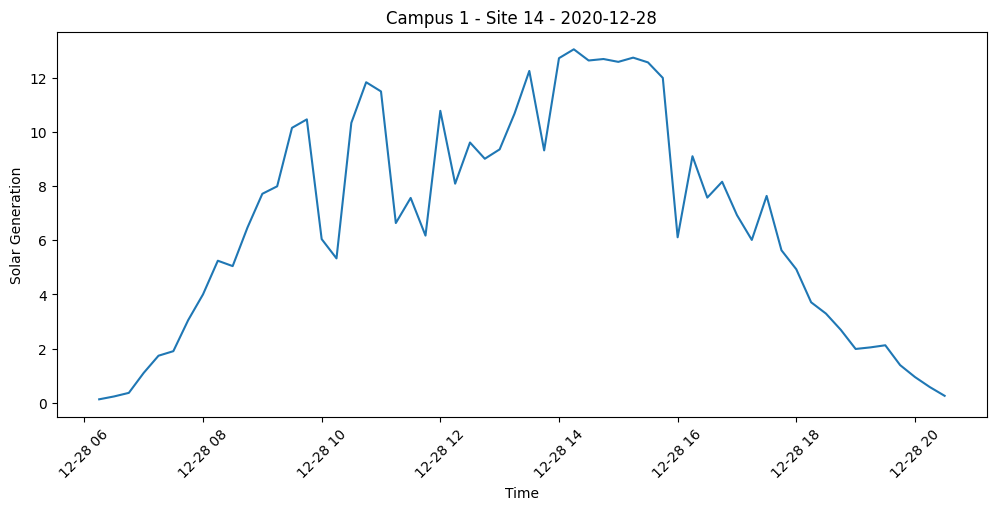

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    sample_day["Timestamp"],
    sample_day["SolarGeneration"]
)

plt.xlabel("Time")
plt.ylabel("Solar Generation")
plt.title(
    f"Campus {chosen_campus} - Site {chosen_site} - {sample_date}"
)

plt.xticks(rotation=45)
plt.show()

##  18. thử chuyển local → UTC

In [36]:
test_time = pd.Timestamp(
    "2020-12-28 14:00:00",
    tz="Australia/Melbourne"
)

print("Local time:", test_time)
print("UTC time:", test_time.tz_convert("UTC"))

Local time: 2020-12-28 14:00:00+11:00
UTC time: 2020-12-28 03:00:00+00:00


In [37]:
#kiểm tra GHI Bundoora
check_ghi = irradiance[
    (irradiance["Campus"] == "Bundoora") &
    (irradiance["Timestamp_UTC"] >= pd.Timestamp(
        "2020-12-28 02:00:00",
        tz="UTC"
    )) &
    (irradiance["Timestamp_UTC"] <= pd.Timestamp(
        "2020-12-28 04:00:00",
        tz="UTC"
    ))
]

check_ghi[
    ["Timestamp_UTC", "Ghi", "CloudOpacity"]
]

,Timestamp_UTC,Ghi,CloudOpacity
8714,2020-12-28 02:00:00+00:00,968,10.8
8715,2020-12-28 03:00:00+00:00,848,18.6
8716,2020-12-28 04:00:00+00:00,883,6.0


## 19. Giữ lại timestamp gốc

In [38]:
solar["Timestamp_Local"] = solar["Timestamp"]
weather["Timestamp_Local"] = weather["Timestamp"]

## 20. Chuyển Solar sang UTC

In [39]:
solar["Timestamp_UTC"] = (
    solar["Timestamp_Local"]
    .dt.tz_localize(
        "Australia/Melbourne",
        ambiguous="NaT",
        nonexistent="NaT"
    )
    .dt.tz_convert("UTC")
)


## 21. Chuyển Weather sang UTC

In [40]:
weather["Timestamp_UTC"] = (
    weather["Timestamp_Local"]
    .dt.tz_localize(
        "Australia/Melbourne",
        ambiguous="NaT",
        nonexistent="NaT"
    )
    .dt.tz_convert("UTC")
)

## 22. Kiểm tra có bao nhiêu NaT do DST

In [41]:
print(
    "Solar UTC NaT:",
    solar["Timestamp_UTC"].isna().sum()
)

print(
    "Weather UTC NaT:",
    weather["Timestamp_UTC"].isna().sum()
)

Solar UTC NaT: 456
Weather UTC NaT: 92


## 23. Kiểm tra ví dụ 28/12/2020

In [42]:
check_solar = solar[
    (solar["CampusKey"] == 1) &
    (solar["SiteKey"] == 14) &
    (
        solar["Timestamp_Local"]
        == pd.Timestamp("2020-12-28 14:00:00")
    )
][
    [
        "Timestamp_Local",
        "Timestamp_UTC",
        "SolarGeneration"
    ]
]

check_solar

,Timestamp_Local,Timestamp_UTC,SolarGeneration
871621,2020-12-28 14:00:00,2020-12-28 03:00:00+00:00,12.746094


## 24. Kiểm tra Solar và Irradiance cùng timestamp

In [43]:
check_compare = check_solar.merge(
    irradiance[
        irradiance["Campus"] == "Bundoora"
    ][
        [
            "Timestamp_UTC",
            "Ghi",
            "CloudOpacity"
        ]
    ],
    on="Timestamp_UTC",
    how="left"
)

check_compare

,Timestamp_Local,Timestamp_UTC,SolarGeneration,Ghi,CloudOpacity
0,2020-12-28 14:00:00,2020-12-28 03:00:00+00:00,12.746094,848,18.6


## 25. Cài và import pvlib

In [44]:
!pip install -q pvlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 54.4 MB/s eta 0:00:00:00:0100:01


In [45]:
import pvlib

## 26. Tạo bảng tọa độ 5 campus

In [46]:
campus_coords = campus_info.copy()

campus_coords["Campus"] = (
    campus_coords["CampusKey"]
    .map(campus_map)
)

campus_coords

,CampusKey,Number_of_Sites,Latitude,Longitude,Campus
0,1,27,-37.718287,145.050975,Bundoora
1,2,5,-36.111209,146.848679,Wodonga
2,3,8,-36.778858,144.301232,Bendigo
3,4,1,-34.205289,142.166556,Mildura
4,5,1,-36.380319,145.406290,Shepparton


## 27. Hàm resample GHI

In [47]:
def resample_irradiance(
    campus_name,
    latitude,
    longitude
):
    # Lấy irradiance của 1 campus
    irr = irradiance[
        irradiance["Campus"] == campus_name
    ][
        [
            "Timestamp_UTC",
            "Ghi",
            "CloudOpacity"
        ]
    ].copy()

    irr = (
        irr
        .dropna(subset=["Timestamp_UTC"])
        .sort_values("Timestamp_UTC")
        .drop_duplicates("Timestamp_UTC")
    )

    # Tạo lưới 15 phút
    time_grid = pd.date_range(
        start=irr["Timestamp_UTC"].min(),
        end=irr["Timestamp_UTC"].max(),
        freq="15min",
        tz="UTC"
    )

    # Location dùng cho clear-sky model
    location = pvlib.location.Location(
        latitude=latitude,
        longitude=longitude,
        tz="UTC",
        name=campus_name
    )

    # Ineichen clear-sky GHI
    clearsky = location.get_clearsky(
        time_grid,
        model="ineichen"
    )

    result = pd.DataFrame({
        "Timestamp_UTC": time_grid,
        "GHI_clear": clearsky["ghi"].values
    })

    # Ghép GHI đo theo giờ vào grid 15 phút
    result = result.merge(
        irr,
        on="Timestamp_UTC",
        how="left"
    )

    # Clearness index
    result["k_t"] = np.nan

    valid = (
        (result["GHI_clear"] > 5) &
        result["Ghi"].notna()
    )

    result.loc[
        valid,
        "k_t"
    ] = (
        result.loc[valid, "Ghi"]
        /
        result.loc[valid, "GHI_clear"]
    )

    # Dùng Timestamp làm index để interpolate theo thời gian
    result = (
        result
        .set_index("Timestamp_UTC")
    )

    result["k_t_interp"] = (
        result["k_t"]
        .interpolate(
            method="time",
            limit_area="inside"
        )
    )

    # Cloud opacity cũng từ 1h -> 15min
    result["CloudOpacity_15min"] = (
        result["CloudOpacity"]
        .interpolate(
            method="time",
            limit_area="inside"
        )
    )

    # Tái tạo GHI 15 phút
    result["GHI_15min"] = (
        result["k_t_interp"]
        *
        result["GHI_clear"]
    )

    # Ban đêm clear-sky gần 0 -> GHI = 0
    result.loc[
        result["GHI_clear"] <= 5,
        "GHI_15min"
    ] = 0

    result = result.reset_index()

    result["Campus"] = campus_name

    return result

## 28. Chạy cho cả 5 campus

In [48]:
irradiance_15min_list = []

for _, row in campus_coords.iterrows():

    print("Processing:", row["Campus"])

    temp_irr = resample_irradiance(
        campus_name=row["Campus"],
        latitude=row["Latitude"],
        longitude=row["Longitude"]
    )

    irradiance_15min_list.append(
        temp_irr
    )

Processing: Bundoora
Processing: Wodonga
Processing: Bendigo
Processing: Mildura
Processing: Shepparton


In [49]:
irradiance_15min = pd.concat(
    irradiance_15min_list,
    ignore_index=True
)

print(
    "Shape:",
    irradiance_15min.shape
)

irradiance_15min.head()

Shape: (409425, 9)


,Timestamp_UTC,GHI_clear,Ghi,CloudOpacity,k_t,k_t_interp,CloudOpacity_15min,GHI_15min,Campus
0,2019-12-31 00:00:00+00:00,877.061511,823.0,15.5,0.938361,0.938361,15.500,823.000000,Bundoora
1,2019-12-31 00:15:00+00:00,909.259220,NaN,NaN,NaN,0.973261,11.625,884.946849,Bundoora
2,2019-12-31 00:30:00+00:00,938.252858,NaN,NaN,NaN,1.008162,7.750,945.910920,Bundoora
3,2019-12-31 00:45:00+00:00,963.911232,NaN,NaN,NaN,1.043063,3.875,1005.419899,Bundoora
4,2019-12-31 01:00:00+00:00,986.118777,1063.0,0.0,1.077963,1.077963,0.000,1063.000000,Bundoora


## 29. Kiểm tra tần suất

In [50]:
(
    irradiance_15min[
        irradiance_15min["Campus"] == "Bundoora"
    ]["Timestamp_UTC"]
    .diff()
    .value_counts()
    .head()
)

Timestamp_UTC
0 days 00:15:00    81884
Name: count, dtype: int64

## 30. Chuẩn bị Solar gốc

In [51]:
solar_obs = solar[
    [
        "CampusKey",
        "SiteKey",
        "Timestamp_UTC",
        "SolarGeneration"
    ]
].copy()

solar_obs = solar_obs.dropna(
    subset=["Timestamp_UTC"]
)

solar_obs["SolarGeneration"] = (
    solar_obs["SolarGeneration"]
    .astype("float32")
)

print(solar_obs.shape)
solar_obs.head()

(2731490, 4)


,CampusKey,SiteKey,Timestamp_UTC,SolarGeneration
0,2,1,2019-12-31 13:15:00+00:00,NaN
1,2,1,2019-12-31 13:30:00+00:00,NaN
2,2,1,2019-12-31 13:45:00+00:00,NaN
3,2,1,2019-12-31 14:00:00+00:00,NaN
4,2,1,2019-12-31 14:15:00+00:00,NaN


## 31. Xem khoảng thời gian của từng site 

In [52]:
site_ranges = (
    solar_obs
    .groupby(["CampusKey", "SiteKey"])["Timestamp_UTC"]
    .agg(["min", "max"])
    .reset_index()
)

site_ranges.head()

,CampusKey,SiteKey,min,max
0,1,14,2020-06-13 14:15:00+00:00,2022-04-23 13:45:00+00:00
1,1,15,2020-06-02 14:15:00+00:00,2022-04-23 13:45:00+00:00
2,1,16,2020-12-08 13:15:00+00:00,2022-04-23 13:45:00+00:00
3,1,17,2020-06-10 14:15:00+00:00,2022-04-23 13:45:00+00:00
4,1,18,2020-07-06 14:15:00+00:00,2022-04-23 13:45:00+00:00


In [53]:
print("Number of sites:", len(site_ranges))

Number of sites: 42


## 32. Tạo lưới 15 phút riêng cho từng site

In [54]:
grid_list = []

for _, row in site_ranges.iterrows():

    time_grid = pd.date_range(
        start=row["min"],
        end=row["max"],
        freq="15min",
        tz="UTC"
    )

    temp_grid = pd.DataFrame({
        "Timestamp_UTC": time_grid
    })

    temp_grid["CampusKey"] = row["CampusKey"]
    temp_grid["SiteKey"] = row["SiteKey"]

    grid_list.append(temp_grid)

In [55]:
# ghép 42 site
solar_grid = pd.concat(
    grid_list,
    ignore_index=True
)

solar_grid["CampusKey"] = (
    solar_grid["CampusKey"]
    .astype("int16")
)

solar_grid["SiteKey"] = (
    solar_grid["SiteKey"]
    .astype("int16")
)

print("Grid shape:", solar_grid.shape)
print(
    "Number of sites:",
    solar_grid[["CampusKey", "SiteKey"]]
    .drop_duplicates()
    .shape[0]
)

solar_grid.head()

Grid shape: (2784514, 3)
Number of sites: 42


,Timestamp_UTC,CampusKey,SiteKey
0,2020-06-13 14:15:00+00:00,1,14
1,2020-06-13 14:30:00+00:00,1,14
2,2020-06-13 14:45:00+00:00,1,14
3,2020-06-13 15:00:00+00:00,1,14
4,2020-06-13 15:15:00+00:00,1,14


## 33. Đưa SolarGeneration vào grid

In [56]:
panel = solar_grid.merge(solar_obs,on=['CampusKey','SiteKey','Timestamp_UTC'],how='left',validate='one_to_one')
panel['SolarGeneration_raw'] = panel['SolarGeneration'].astype('float32')
panel['SolarObserved'] = panel['SolarGeneration_raw'].notna()
panel['SolarObservedValid'] = panel['SolarObserved'] & panel['SolarGeneration_raw'].ge(0)
panel['ImputationSource'] = np.where(panel['SolarObserved'], 'observed', 'missing')
print(panel.shape)

(2784514, 8)


In [57]:
print(
    "Missing SolarGeneration:",
    panel["SolarGeneration"].isna().sum()
)

print(
    "Missing percent:",
    panel["SolarGeneration"].isna().mean() * 100
)

Missing SolarGeneration: 1588869
Missing percent: 57.06090901320662


## 34. Tạo SiteID và tên Campus

In [58]:
panel["SiteID"] = (
    panel["CampusKey"].astype(str)
    + "_"
    + panel["SiteKey"].astype(str)
)

panel["Campus"] = (
    panel["CampusKey"]
    .map(campus_map)
)

In [59]:
panel[
    [
        "CampusKey",
        "SiteKey",
        "SiteID",
        "Campus"
    ]
].drop_duplicates().head(10)

,CampusKey,SiteKey,SiteID,Campus
0,1,14,1_14,Bundoora
65183,1,15,1_15,Bundoora
131422,1,16,1_16,Bundoora
179521,1,17,1_17,Bundoora
244992,1,18,1_18,Bundoora
307967,1,19,1_19,Bundoora
372094,1,20,1_20,Bundoora
437565,1,21,1_21,Bundoora
503036,1,22,1_22,Bundoora
568507,1,23,1_23,Bundoora


## 35. Ghép metadata của PV site

In [60]:
site_meta = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Number of panels",
        "lat",
        "Lon"
    ]
].copy()

In [61]:
# merge
panel = panel.merge(
    site_meta,
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

print(panel.shape)
panel.head()

(2784514, 14)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration,SolarGeneration_raw,SolarObserved,SolarObservedValid,ImputationSource,SiteID,Campus,kWp,Number of panels,lat,Lon
0,2020-06-13 14:15:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
1,2020-06-13 14:30:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
2,2020-06-13 14:45:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
3,2020-06-13 15:00:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
4,2020-06-13 15:15:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975


## 36. Chuẩn bị Weather

In [62]:
weather_merge = weather[
    [
        "CampusKey",
        "Timestamp_UTC",
        "ApparentTemperature",
        "AirTemperature",
        "DewPointTemperature",
        "RelativeHumidity",
        "WindSpeed",
        "WindDirection"
    ]
].copy()

weather_merge = weather_merge.dropna(
    subset=["Timestamp_UTC"]
)

In [63]:
# Đổi float64 → float32 để đỡ RAM
weather_float_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDirection"
]

weather_merge[weather_float_cols] = (
    weather_merge[weather_float_cols]
    .astype("float32")
)

In [64]:
print(
    weather_merge.duplicated(
        subset=[
            "CampusKey",
            "Timestamp_UTC"
        ]
    ).sum()
)

0


## 37. Merge Weather vào 42 sites

In [65]:
panel = panel.merge(
    weather_merge,
    on=[
        "CampusKey",
        "Timestamp_UTC"
    ],
    how="left",
    validate="many_to_one"
)

print(panel.shape)

panel.head()

(2784514, 20)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration,SolarGeneration_raw,SolarObserved,SolarObservedValid,ImputationSource,SiteID,Campus,kWp,Number of panels,lat,Lon,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
0,2020-06-13 14:15:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.140000,12.853333,12.626667,98.733330,7.880000,21.133333
1,2020-06-13 14:30:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.740000,12.700000,12.500000,99.000000,3.720000,55.400002
2,2020-06-13 14:45:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.253333,12.593333,12.393333,99.000000,5.706666,63.933334
3,2020-06-13 15:00:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,11.593333,12.613334,12.413333,99.000000,9.133333,151.600006
4,2020-06-13 15:15:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,10.973333,12.820000,12.046667,95.133331,12.760000,341.266663


## 38. Chuẩn bị Irradiance 15 phút

In [66]:
irr_merge = irradiance_15min[
    [
        "Campus",
        "Timestamp_UTC",
        "GHI_clear",
        "GHI_15min",
        "k_t_interp",
        "CloudOpacity_15min"
    ]
].copy()
irr_cols = [
    "GHI_clear",
    "GHI_15min",
    "k_t_interp",
    "CloudOpacity_15min"
]

irr_merge[irr_cols] = (
    irr_merge[irr_cols]
    .astype("float32")
)

In [67]:
print(
    irr_merge.duplicated(
        subset=[
            "Campus",
            "Timestamp_UTC"
        ]
    ).sum()
)

0


## 39. Merge Irradiance

In [68]:
panel = panel.merge(
    irr_merge,
    on=[
        "Campus",
        "Timestamp_UTC"
    ],
    how="left",
    validate="many_to_one"
)

print("Final panel shape:", panel.shape)

panel.head()

Final panel shape: (2784514, 24)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration,SolarGeneration_raw,SolarObserved,SolarObservedValid,ImputationSource,SiteID,Campus,kWp,Number of panels,lat,Lon,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection,GHI_clear,GHI_15min,k_t_interp,CloudOpacity_15min
0,2020-06-13 14:15:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.140000,12.853333,12.626667,98.733330,7.880000,21.133333,0.0,0.0,3.129371,79.074997
1,2020-06-13 14:30:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.740000,12.700000,12.500000,99.000000,3.720000,55.400002,0.0,0.0,3.213690,80.349998
2,2020-06-13 14:45:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.253333,12.593333,12.393333,99.000000,5.706666,63.933334,0.0,0.0,3.298009,81.625000
3,2020-06-13 15:00:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,11.593333,12.613334,12.413333,99.000000,9.133333,151.600006,0.0,0.0,3.382328,82.900002
4,2020-06-13 15:15:00+00:00,1,14,NaN,NaN,False,False,missing,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,10.973333,12.820000,12.046667,95.133331,12.760000,341.266663,0.0,0.0,3.466646,78.175003


## 40. Kiểm tra panel có đúng 42 site không

In [69]:
print(
    "Number of sites:",
    panel["SiteID"].nunique()
)

print(
    "Number of campuses:",
    panel["Campus"].nunique()
)

Number of sites: 42
Number of campuses: 5


## 41. Kiểm tra missing sau khi ghép

In [70]:
missing_summary(panel)

,Missing,Missing_Percent
SolarGeneration,1588869,57.060909
SolarGeneration_raw,1588869,57.060909
WindDirection,1197100,42.991344
WindSpeed,1197100,42.991344
kWp,1155115,41.483541
Number of panels,1155115,41.483541
RelativeHumidity,637432,22.892038
DewPointTemperature,637432,22.892038
ApparentTemperature,637432,22.892038
AirTemperature,637432,22.892038


In [71]:
important_cols = [
    "SolarGeneration",
    "GHI_15min",
    "GHI_clear",
    "AirTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "CloudOpacity_15min",
    "kWp"
]

missing_summary(
    panel[important_cols]
)

,Missing,Missing_Percent
SolarGeneration,1588869,57.060909
WindSpeed,1197100,42.991344
kWp,1155115,41.483541
AirTemperature,637432,22.892038
RelativeHumidity,637432,22.892038
GHI_15min,0,0.000000
GHI_clear,0,0.000000
CloudOpacity_15min,0,0.000000


## 42. Sắp xếp panel 

In [72]:
panel = (
    panel
    .sort_values(
        ["SiteID", "Timestamp_UTC"]
    )
    .reset_index(drop=True)
)

print(panel.shape)

(2784514, 24)


## 43. Tính Solar Elevation cho 42 site

In [73]:
panel["SolarElevation"] = np.nan

for site_id, idx in panel.groupby("SiteID").groups.items():

    lat = panel.loc[idx, "lat"].iloc[0]
    lon = panel.loc[idx, "Lon"].iloc[0]

    times = pd.DatetimeIndex(
        panel.loc[idx, "Timestamp_UTC"]
    )

    solar_pos = pvlib.solarposition.get_solarposition(
        time=times,
        latitude=lat,
        longitude=lon
    )

    panel.loc[idx, "SolarElevation"] = (
        solar_pos["elevation"].to_numpy()
    )

print(
    panel["SolarElevation"]
    .describe()
)

count    2.784514e+06
mean     7.934626e-01
std      3.744103e+01
min     -7.921172e+01
25%     -2.948261e+01
50%      6.590555e-01
75%      3.079987e+01
max      7.923090e+01
Name: SolarElevation, dtype: float64


In [74]:
#giảm  RAM
panel["SolarElevation"] = (
    panel["SolarElevation"]
    .astype("float32")
)

## 44. Tạo biến Night

In [75]:
GHI_THRESHOLD = 5.0

panel["Night"] = (
    (panel["SolarElevation"] <= 0) |
    (panel["GHI_15min"] < GHI_THRESHOLD)
).astype("int8")

In [76]:
panel["Night"].value_counts()

Night
1    1436702
0    1347812
Name: count, dtype: int64

In [77]:
panel["Night"].value_counts(
    normalize=True
) * 100

Night
1    51.596149
0    48.403851
Name: proportion, dtype: float64

## 45. Tách Solar missing ban đêm và ban ngày

In [78]:
night_missing = (
    panel["SolarGeneration"].isna()
    &
    (panel["Night"] == 1)
)

day_missing = (
    panel["SolarGeneration"].isna()
    &
    (panel["Night"] == 0)
)

print(
    "Total Solar missing:",
    panel["SolarGeneration"].isna().sum()
)

print(
    "Night missing:",
    night_missing.sum()
)

print(
    "Daytime missing:",
    day_missing.sum()
)

Total Solar missing: 1588869
Night missing: 1415651
Daytime missing: 173218


In [79]:
print(
    "Night missing %:",
    night_missing.mean() * 100
)

print(
    "Daytime missing %:",
    day_missing.mean() * 100
)

Night missing %: 50.84014661086279
Daytime missing %: 6.22076240234382


## 46. Điền 0 CHỈ cho missing ban đêm

In [80]:
panel.loc[
    night_missing,
    "SolarGeneration"
] = 0.0
panel.loc[
    night_missing,
    "ImputationSource"
] = "night_zero"

In [81]:
print(
    "Solar missing sau khi xử lý nighttime:",
    panel["SolarGeneration"].isna().sum()
)

Solar missing sau khi xử lý nighttime: 173218


## 47. Kiểm tra giá trị Solar bất thường

In [82]:
print(
    "Negative SolarGeneration:",
    (panel["SolarGeneration"] < 0).sum()
)

print(
    panel["SolarGeneration"].describe()
)

Negative SolarGeneration: 0
count    2.611296e+06
mean     3.179691e+00
std      8.334717e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      2.792969e+00
max      9.921880e+01
Name: SolarGeneration, dtype: float64


In [83]:
print(
    "Sites có kWp:",
    site["kWp"].notna().sum()
)

print(
    "Sites thiếu kWp:",
    site["kWp"].isna().sum()
)

Sites có kWp: 25
Sites thiếu kWp: 17


In [84]:
site["Metric"].value_counts(
    dropna=False
)

Metric
kWh    25
NaN    17
Name: count, dtype: int64

## 48. Tạo lại giờ địa phương

In [85]:
panel["Timestamp_Local"] = (
    panel["Timestamp_UTC"]
    .dt.tz_convert("Australia/Melbourne")
)

panel["Hour"] = (
    panel["Timestamp_Local"].dt.hour
).astype("int8")

panel["Month"] = (
    panel["Timestamp_Local"].dt.month
).astype("int8")

panel["DayOfYear"] = (
    panel["Timestamp_Local"].dt.dayofyear
).astype("int16")

In [86]:
panel[
    [
        "Timestamp_UTC",
        "Timestamp_Local",
        "Hour",
        "Month",
        "DayOfYear"
    ]
].head()

,Timestamp_UTC,Timestamp_Local,Hour,Month,DayOfYear
0,2020-06-13 14:15:00+00:00,2020-06-14 00:15:00+10:00,0,6,166
1,2020-06-13 14:30:00+00:00,2020-06-14 00:30:00+10:00,0,6,166
2,2020-06-13 14:45:00+00:00,2020-06-14 00:45:00+10:00,0,6,166
3,2020-06-13 15:00:00+00:00,2020-06-14 01:00:00+10:00,1,6,166
4,2020-06-13 15:15:00+00:00,2020-06-14 01:15:00+10:00,1,6,166


In [87]:
# lấy timeline chung
unique_times = (
    pd.Series(
        panel["Timestamp_UTC"]
        .dropna()
        .unique()
    )
    .sort_values()
    .reset_index(drop=True)
)

n_time = len(unique_times)

print("Number of timestamps:", n_time)
print("Start:", unique_times.iloc[0])
print("End:", unique_times.iloc[-1])

Number of timestamps: 81027
Start: 2019-12-31 13:15:00+00:00
End: 2022-04-23 13:45:00+00:00


In [88]:
# EXPERIMENT B: khoảng 70% train / 10% validation / 20% test
# Tỷ lệ tính trên timeline còn lại sau hai gap.

GAP_RATIO = 0.05

gap_n = int(n_time * GAP_RATIO)
usable_n = n_time - 2 * gap_n

# Cách chia A để giữ chính xác giai đoạn test cũ
train_n_A = int(usable_n * 0.60)
val_n_A = int(usable_n * 0.20)

test_n_A = (
    usable_n
    - train_n_A
    - val_n_A
)

# Cách chia B
train_n = int(usable_n * 0.70)
test_n = test_n_A
val_n = usable_n - train_n - test_n

# Kiểm tra mốc bắt đầu test không thay đổi
test_start_idx_A = (
    train_n_A + gap_n + val_n_A + gap_n
)

test_start_idx_B = (
    train_n + gap_n + val_n + gap_n
)

assert test_start_idx_A == test_start_idx_B
assert train_n + val_n + test_n + 2 * gap_n == n_time

print("EXPERIMENT B")
print("Train timestamps:", train_n)
print("Gap 1:", gap_n)
print("Validation timestamps:", val_n)
print("Gap 2:", gap_n)
print("Test timestamps:", test_n)
print(
    "Test bắt đầu:",
    unique_times.iloc[test_start_idx_B]
)

EXPERIMENT B
Train timestamps: 51047
Gap 1: 4051
Validation timestamps: 7293
Gap 2: 4051
Test timestamps: 14585
Test bắt đầu: 2021-11-22 15:45:00+00:00


In [89]:
#xác định các mốc thời gian
train_end_idx = (
    train_n - 1
)

gap1_end_idx = (
    train_n
    + gap_n
    - 1
)

val_end_idx = (
    train_n
    + gap_n
    + val_n
    - 1
)

gap2_end_idx = (
    train_n
    + gap_n
    + val_n
    + gap_n
    - 1
)

train_end = unique_times.iloc[
    train_end_idx
]

gap1_end = unique_times.iloc[
    gap1_end_idx
]

val_end = unique_times.iloc[
    val_end_idx
]

gap2_end = unique_times.iloc[
    gap2_end_idx
]
print("Train end:", train_end)
print("Gap 1 end:", gap1_end)
print("Validation end:", val_end)
print("Gap 2 end:", gap2_end)
print("Test end:", unique_times.iloc[-1])

Train end: 2021-06-15 06:45:00+00:00
Gap 1 end: 2021-07-27 11:30:00+00:00
Validation end: 2021-10-11 10:45:00+00:00
Gap 2 end: 2021-11-22 15:30:00+00:00
Test end: 2022-04-23 13:45:00+00:00


In [90]:
#gắn nhãn train/validation/test
panel["Split"] = "gap"

panel.loc[
    panel["Timestamp_UTC"] <= train_end,
    "Split"
] = "train"

panel.loc[
    (panel["Timestamp_UTC"] > gap1_end)
    &
    (panel["Timestamp_UTC"] <= val_end),
    "Split"
] = "validation"

panel.loc[
    panel["Timestamp_UTC"] > gap2_end,
    "Split"
] = "test"

panel["Split"].value_counts()

Split
train         1525354
test           612570
gap            340284
validation     306306
Name: count, dtype: int64

In [91]:
for split_name in [
    "train",
    "validation",
    "test"
]:
    temp = panel[
        panel["Split"] == split_name
    ]

    print(
        "\n",
        split_name.upper()
    )

    print(
        "Rows:",
        len(temp)
    )

    print(
        "Start:",
        temp["Timestamp_UTC"].min()
    )

    print(
        "End:",
        temp["Timestamp_UTC"].max()
    )


 TRAIN
Rows: 1525354
Start: 2019-12-31 13:15:00+00:00
End: 2021-06-15 06:45:00+00:00

 VALIDATION
Rows: 306306
Start: 2021-07-27 11:45:00+00:00
End: 2021-10-11 10:45:00+00:00

 TEST
Rows: 612570
Start: 2021-11-22 15:45:00+00:00
End: 2022-04-23 13:45:00+00:00


## 49. Tạo DataStatus cơ bản

In [92]:
panel['DataStatus'] = ~(panel['SolarGeneration_raw'].lt(0))
panel.loc[~panel['DataStatus'],'SolarGeneration'] = np.nan
# Capacity/ramp hiện là CHẨN ĐOÁN. Chưa có ngưỡng của tác giả và metadata đủ tin cậy.
# Không âm thầm coi mọi điểm vượt kWp*0.25 là lỗi để ép số liệu khớp bài báo.
print('Invalid negative observations:', (~panel['DataStatus']).sum())

Invalid negative observations: 0


## 50. Chuẩn bị capacity cho 25 site có dữ liệu

In [93]:
capacity_info = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Metric"
    ]
].copy()

In [94]:
# chỉ những site có Metric = kWh và kWp không missing mới có bound
capacity_info["Capacity_15min"] = np.where(
    (capacity_info["Metric"] == "kWh")
    &
    (capacity_info["kWp"].notna()),
    
    capacity_info["kWp"] * 0.25,
    
    np.nan
)

In [95]:
#merge vào panel
panel = panel.merge(
    capacity_info[
        [
            "CampusKey",
            "SiteKey",
            "Capacity_15min"
        ]
    ],
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

## 51. Xem có bao nhiêu giá trị vượt capacity

In [96]:
capacity_available = (
    panel["Capacity_15min"].notna()
    &
    panel["SolarGeneration"].notna()
)

capacity_ratio = (
    panel.loc[
        capacity_available,
        "SolarGeneration"
    ]
    /
    panel.loc[
        capacity_available,
        "Capacity_15min"
    ]
)

capacity_ratio.describe(
    percentiles=[
        0.90,
        0.95,
        0.99,
        0.999
    ]
)

count    1.538410e+06
mean     1.638944e-01
std      3.666730e-01
min      0.000000e+00
50%      0.000000e+00
90%      5.209713e-01
95%      6.860808e-01
99%      1.533362e+00
99.9%    4.414336e+00
max      4.920600e+00
dtype: float64

## 52. xem site nào có capacity ratio cao

In [97]:
capacity_check = panel.loc[
    capacity_available,
    [
        "CampusKey",
        "SiteKey",
        "SiteID",
        "Timestamp_UTC",
        "SolarGeneration",
        "Capacity_15min",
        "GHI_15min"
    ]
].copy()

capacity_check["CapacityRatio"] = (
    capacity_check["SolarGeneration"]
    / capacity_check["Capacity_15min"]
)
capacity_check.sort_values(
    "CapacityRatio",
    ascending=False
).head(20)

,CampusKey,SiteKey,SiteID,Timestamp_UTC,SolarGeneration,Capacity_15min,GHI_15min,CapacityRatio
355532,1,19,1_19,2021-11-02 01:30:00+00:00,42.218750,8.58,991.302246,4.920600
323178,1,19,1_19,2020-11-30 01:00:00+00:00,42.218750,8.58,1036.000000,4.920600
358417,1,19,1_19,2021-12-02 02:45:00+00:00,42.218750,8.58,896.390869,4.920600
324042,1,19,1_19,2020-12-09 01:00:00+00:00,42.218750,8.58,1049.000000,4.920600
363020,1,19,1_19,2022-01-19 01:30:00+00:00,42.218750,8.58,1047.869019,4.920600
360915,1,19,1_19,2021-12-28 03:15:00+00:00,42.218750,8.58,994.906128,4.920600
361393,1,19,1_19,2022-01-02 02:45:00+00:00,42.218750,8.58,992.763245,4.920600
354963,1,19,1_19,2021-10-27 03:15:00+00:00,42.218750,8.58,903.047424,4.920600
365142,1,19,1_19,2022-02-10 04:00:00+00:00,42.218750,8.58,880.000000,4.920600
354386,1,19,1_19,2021-10-21 03:00:00+00:00,42.218750,8.58,866.000000,4.920600


In [98]:
capacity_by_site = (
    capacity_check
    .groupby("SiteID")
    .agg(
        Max_Ratio=("CapacityRatio", "max"),
        P99_Ratio=("CapacityRatio", lambda x: x.quantile(0.99)),
        Rows=("CapacityRatio", "size")
    )
    .sort_values("Max_Ratio", ascending=False)
)

capacity_by_site.head(15)

,Max_Ratio,P99_Ratio,Rows
SiteID,,,
1_19,4.920600,4.743954,61003
1_24,1.766642,1.689574,62406
1_33,0.859037,0.821740,62354
1_31,0.851043,0.817428,62362
1_17,0.843736,0.809213,62004
1_18,0.840924,0.809203,60167
1_25,0.835676,0.808341,60985
1_22,0.828490,0.789574,62203
1_32,0.825968,0.779935,61767


## 53. kiểm tra missing Weather còn lại

In [99]:
weather_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDirection"
]

missing_summary(
    panel[weather_cols]
)

,Missing,Missing_Percent
WindSpeed,1197100,42.991344
WindDirection,1197100,42.991344
AirTemperature,637432,22.892038
ApparentTemperature,637432,22.892038
RelativeHumidity,637432,22.892038
DewPointTemperature,637432,22.892038


## 54. interpolation Weather theo từng campus

In [100]:
weather_panel = (panel[['CampusKey','Timestamp_UTC','Split']+weather_cols]
    .drop_duplicates(['CampusKey','Timestamp_UTC'])
    .sort_values(['CampusKey','Timestamp_UTC']).reset_index(drop=True))

In [101]:
weather_panel.shape

(405135, 9)

In [102]:
# Quy ước tái dựng bổ sung: ngưỡng 4 bước là lựa chọn triển khai, tác giả không nêu chính xác.
# Hướng gió xử lý ở mục 57 bằng sin/cos, không nội suy trực tiếp góc 359 -> 1 độ.
for col in [c for c in weather_cols if c!='WindDirection']:
    weather_panel[col] = weather_panel.groupby(['CampusKey','Split'],sort=False)[col].ffill(limit=4)
display(missing_summary(weather_panel[weather_cols]))

,Missing,Missing_Percent
WindDirection,196288,48.450023
WindSpeed,196224,48.434226
AirTemperature,86833,21.433103
ApparentTemperature,86833,21.433103
RelativeHumidity,86833,21.433103
DewPointTemperature,86833,21.433103


## 55. chuẩn bị IterativeImputer

In [103]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

weather_impute_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed"
]

## 56. IterativeImputer theo từng campus

In [104]:
train_weather = weather_panel.loc[weather_panel['Split'].eq('train'),weather_impute_cols]
weather_global_median = train_weather.median()
if weather_global_median.isna().any():
    raise ValueError('Có biến weather hoàn toàn thiếu trong TRAIN: '+str(weather_global_median[weather_global_median.isna()].index.tolist()))
weather_models={}
for campus_key, idx in weather_panel.groupby('CampusKey').groups.items():
    block=weather_panel.loc[idx,weather_impute_cols].copy()
    fit_mask=weather_panel.loc[idx,'Split'].eq('train')
    fit=block.loc[fit_mask].copy()
    if fit.empty:
        weather_panel.loc[idx,weather_impute_cols]=block.fillna(weather_global_median).to_numpy()
        weather_models[int(campus_key)]=None
        continue
    empty_cols=fit.columns[fit.isna().all()]
    for col in empty_cols:
        fit[col]=weather_global_median[col]
        block[col]=block[col].fillna(weather_global_median[col])
    imputer=IterativeImputer(max_iter=10,random_state=SEED,initial_strategy='median',skip_complete=False)
    imputer.fit(fit)
    weather_panel.loc[idx,weather_impute_cols]=imputer.transform(block)
    weather_models[int(campus_key)]=imputer
# Giới hạn hiển nhiên của weather; cùng quy tắc cho mọi Split.
weather_panel['RelativeHumidity']=weather_panel['RelativeHumidity'].clip(0,100)
weather_panel['WindSpeed']=weather_panel['WindSpeed'].clip(lower=0)
assert weather_panel[weather_impute_cols].notna().all().all()

In [105]:
missing_summary(
    weather_panel[weather_impute_cols]
)

,Missing,Missing_Percent
ApparentTemperature,0,0.0
AirTemperature,0,0.0
DewPointTemperature,0,0.0
RelativeHumidity,0,0.0
WindSpeed,0,0.0


## 57. WindDirection xử lý riêng

In [106]:
# với hướng gió, dùng circular representation
angle_rad = np.deg2rad(
    weather_panel["WindDirection"]
)

weather_panel["WindDir_sin"] = np.sin(angle_rad)
weather_panel["WindDir_cos"] = np.cos(angle_rad)

In [107]:
for col in ['WindDir_sin','WindDir_cos']:
    weather_panel[col]=weather_panel.groupby(['CampusKey','Split'],sort=False)[col].ffill(limit=4)
    train_part=weather_panel.loc[weather_panel['Split'].eq('train')]
    med=train_part.groupby('CampusKey')[col].median()
    global_med=train_part[col].median()
    if pd.isna(global_med):
        raise ValueError('Không có hướng gió quan sát trong TRAIN.')
    weather_panel[col]=weather_panel[col].fillna(weather_panel['CampusKey'].map(med)).fillna(global_med)
r=np.hypot(weather_panel['WindDir_sin'],weather_panel['WindDir_cos'])
valid=r.gt(1e-8)
weather_panel.loc[valid,'WindDir_sin']/=r[valid]
weather_panel.loc[valid,'WindDir_cos']/=r[valid]
# Không xác định hướng khi vector trung vị gần 0: giữ (0,0).

In [108]:
weather_panel[
    ["WindDir_sin", "WindDir_cos"]
].isna().sum()

WindDir_sin    0
WindDir_cos    0
dtype: int64

## 58. Đưa Weather đã xử lý trở lại panel

In [109]:
# xóa các cột Weather cũ đang missing
old_weather_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDirection"
]

panel = panel.drop(
    columns=old_weather_cols,
    errors="ignore"
)
# Lấy Weather sạch
weather_clean = weather_panel[
    [
        "CampusKey",
        "Timestamp_UTC",
        "ApparentTemperature",
        "AirTemperature",
        "DewPointTemperature",
        "RelativeHumidity",
        "WindSpeed",
        "WindDir_sin",
        "WindDir_cos"
    ]
].copy()
#merge
panel = panel.merge(
    weather_clean,
    on=[
        "CampusKey",
        "Timestamp_UTC"
    ],
    how="left",
    validate="many_to_one"
)

In [110]:
missing_summary(
    panel[
        [
            "ApparentTemperature",
            "AirTemperature",
            "DewPointTemperature",
            "RelativeHumidity",
            "WindSpeed",
            "WindDir_sin",
            "WindDir_cos"
        ]
    ]
)

,Missing,Missing_Percent
ApparentTemperature,0,0.0
AirTemperature,0,0.0
DewPointTemperature,0,0.0
RelativeHumidity,0,0.0
WindSpeed,0,0.0
WindDir_sin,0,0.0
WindDir_cos,0,0.0


## 59. Tạo các feature thời gian

In [111]:
# Tạo cyclical features
panel["Hour_sin"] = np.sin(
    2 * np.pi * panel["Hour"] / 24
)

panel["Hour_cos"] = np.cos(
    2 * np.pi * panel["Hour"] / 24
)

panel["Day_sin"] = np.sin(
    2 * np.pi * panel["DayOfYear"] / 365.25
)

panel["Day_cos"] = np.cos(
    2 * np.pi * panel["DayOfYear"] / 365.25
)

In [112]:
# Đổi sang float32 để tiết kiệm RAM
for col in [
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos"
]:
    panel[col] = panel[col].astype("float32")

In [113]:
# Kiểm tra Solar missing hiện tại
print(
    "Solar missing còn lại:",
    panel["SolarGeneration"].isna().sum()
)

print(
    "Daytime missing:",
    (
        panel["SolarGeneration"].isna()
        &
        (panel["Night"] == 0)
    ).sum()
)


Solar missing còn lại: 173218
Daytime missing: 173218


## 60. Các feature dùng để impute Solar ban ngày

In [114]:
solar_impute_cols = [
    "SolarGeneration",

    # Irradiance
    "GHI_15min",
    "GHI_clear",
    "k_t_interp",
    "CloudOpacity_15min",
    "SolarElevation",

    # Weather
    "AirTemperature",
    "ApparentTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDir_sin",
    "WindDir_cos",

    # Time
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos"
]
panel[
    solar_impute_cols[1:]
].isna().sum()

GHI_15min              0
GHI_clear              0
k_t_interp             0
CloudOpacity_15min     0
SolarElevation         0
AirTemperature         0
ApparentTemperature    0
DewPointTemperature    0
RelativeHumidity       0
WindSpeed              0
WindDir_sin            0
WindDir_cos            0
Hour_sin               0
Hour_cos               0
Day_sin                0
Day_cos                0
dtype: int64

## 61. Backup SolarGeneration trước khi impute

In [115]:
panel['SolarGeneration_before_impute']=panel['SolarGeneration'].astype('float32')
assert 'SolarGeneration_raw' in panel and 'SolarObservedValid' in panel

## 62. Iterative Imputation theo từng Site

In [116]:
solar_models={}
train_day=panel.loc[panel['Split'].eq('train') & panel['Night'].eq(0) & panel['SolarObservedValid']]
global_pv_median=train_day['SolarGeneration_raw'].median()
if pd.isna(global_pv_median):
    raise ValueError('TRAIN không có sản lượng đo thật ban ngày.')
for site_id, idx in panel.groupby('SiteID').groups.items():
    idx=pd.Index(idx)
    day_idx=idx[panel.loc[idx,'Night'].eq(0).to_numpy()]
    missing_idx=day_idx[panel.loc[day_idx,'SolarGeneration'].isna().to_numpy()]
    if len(missing_idx)==0:
        continue
    fit_idx=day_idx[panel.loc[day_idx,'Split'].eq('train').to_numpy()]
    n_observed=panel.loc[fit_idx,'SolarGeneration'].notna().sum()
    filled=pd.Series(np.nan,index=missing_idx,dtype=float)
    if n_observed>=50:
        fit=panel.loc[fit_idx,solar_impute_cols]
        low=np.full(len(solar_impute_cols),-np.inf); low[0]=0.0
        imputer=IterativeImputer(max_iter=10,random_state=SEED,initial_strategy='median',skip_complete=False,min_value=low)
        imputer.fit(fit)
        values=imputer.transform(panel.loc[missing_idx,solar_impute_cols])[:,0]
        filled.loc[:]=values
        solar_models[str(site_id)]=imputer
    # Median month x hour -> hour -> site -> global, đều chỉ học số đo TRAIN.
    site_train=train_day.loc[train_day['SiteID'].eq(site_id)]
    month_hour=site_train.groupby(['Month','Hour'])['SolarGeneration_raw'].median()
    hour_med=site_train.groupby('Hour')['SolarGeneration_raw'].median()
    query=pd.MultiIndex.from_frame(panel.loc[missing_idx,['Month','Hour']])
    fallback=pd.Series(month_hour.reindex(query).to_numpy(),index=missing_idx)
    fallback=fallback.fillna(panel.loc[missing_idx,'Hour'].map(hour_med))
    fallback=fallback.fillna(site_train['SolarGeneration_raw'].median()).fillna(global_pv_median)
    use_fallback=~np.isfinite(filled)
    filled=filled.mask(use_fallback,fallback).clip(lower=0)
    panel.loc[missing_idx,'SolarGeneration']=filled.to_numpy()
    panel.loc[missing_idx,'ImputationSource']=np.where(use_fallback,'train_median','train_iterative')
    print(site_id,'| thiếu:',len(missing_idx),'| số đo TRAIN:',n_observed)
assert panel['SolarGeneration'].notna().all()
# Không đánh giá giá trị vừa ước lượng như thể đó là số đo gốc.

1_14 | thiếu: 3922 | số đo TRAIN: 14804
1_15 | thiếu: 3067 | số đo TRAIN: 15168
1_16 | thiếu: 4060 | số đo TRAIN: 7141
1_17 | thiếu: 3467 | số đo TRAIN: 14669
1_18 | thiếu: 2808 | số đo TRAIN: 14076
1_19 | thiếu: 3124 | số đo TRAIN: 14283
1_20 | thiếu: 3306 | số đo TRAIN: 14828
1_21 | thiếu: 3737 | số đo TRAIN: 14466
1_22 | thiếu: 3268 | số đo TRAIN: 14776
1_23 | thiếu: 3257 | số đo TRAIN: 12566
1_24 | thiếu: 3065 | số đo TRAIN: 14873
1_25 | thiếu: 3142 | số đo TRAIN: 14332
1_26 | thiếu: 3685 | số đo TRAIN: 14382
1_27 | thiếu: 5972 | số đo TRAIN: 18898
1_28 | thiếu: 5451 | số đo TRAIN: 11744
1_29 | thiếu: 5486 | số đo TRAIN: 12011
1_30 | thiếu: 3612 | số đo TRAIN: 12414
1_31 | thiếu: 3109 | số đo TRAIN: 14851
1_32 | thiếu: 3704 | số đo TRAIN: 14522
1_33 | thiếu: 3117 | số đo TRAIN: 14842
1_34 | thiếu: 4722 | số đo TRAIN: 16991
1_35 | thiếu: 6106 | số đo TRAIN: 15764
1_36 | thiếu: 3421 | số đo TRAIN: 14651
1_37 | thiếu: 3219 | số đo TRAIN: 14825
1_38 | thiếu: 3117 | số đo TRAIN: 14663
1

In [117]:
# Kiểm tra Solar missing sau IterativeImputer
print(
    "Missing Solar after iterative imputation:",
    panel["SolarGeneration"].isna().sum()
)

Missing Solar after iterative imputation: 0


## 63. Kiểm tra tính vật lý sau imputation

In [118]:
print(
    "Negative:",
    (panel["SolarGeneration"] < 0).sum()
)

print(
    panel["SolarGeneration"].describe()
)

Negative: 0
count    2.784514e+06
mean     3.422651e+00
std      8.808110e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.171875e+00
max      9.921880e+01
Name: SolarGeneration, dtype: float64


In [119]:
panel["SolarGeneration"] = (
    panel["SolarGeneration"]
    .clip(lower=0)
)

## 64. Clear-sky index

In [120]:
panel["ClearSkyIndex"] = (
    panel["GHI_15min"]
    /
    panel["GHI_clear"].replace(0, np.nan)
)

panel["ClearSkyIndex"] = (
    panel["ClearSkyIndex"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .clip(lower=0)
    .astype("float32")
)

## 65. Normalized GHI

In [121]:
panel["GHI_Normalized"] = (
    panel["GHI_15min"]
    /
    (panel["GHI_clear"] + 1e-6)
)

panel["GHI_Normalized"] = (
    panel["GHI_Normalized"]
    .clip(lower=0)
    .astype("float32")
)

## 66. Temperature difference

In [122]:
panel["TempDiff"] = (
    panel["ApparentTemperature"]
    -
    panel["AirTemperature"]
).astype("float32")

## 67. Vapor pressure

In [123]:
panel["VaporPressure"] = (
    0.6108 *
    np.exp(
        (17.27 * panel["DewPointTemperature"])
        /
        (panel["DewPointTemperature"] + 237.3)
    )
).astype("float32")

## 68. Cyclical time features

In [124]:
panel["Hour_sin"] = np.sin(
    2 * np.pi * panel["Hour"] / 24
).astype("float32")

panel["Hour_cos"] = np.cos(
    2 * np.pi * panel["Hour"] / 24
).astype("float32")

panel["Day_sin"] = np.sin(
    2 * np.pi * panel["DayOfYear"] / 365.25
).astype("float32")

panel["Day_cos"] = np.cos(
    2 * np.pi * panel["DayOfYear"] / 365.25
).astype("float32")

## 69. Kiểm tra các physics features

In [125]:
physics_cols = [
    "GHI_15min",
    "GHI_clear",
    "ClearSkyIndex",
    "GHI_Normalized",
    "SolarElevation",
    "TempDiff",
    "VaporPressure"
]

panel[physics_cols].describe()

,GHI_15min,GHI_clear,ClearSkyIndex,GHI_Normalized,SolarElevation,TempDiff,VaporPressure
count,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06
mean,1.928356e+02,2.472660e+02,4.354455e-01,4.354455e-01,7.934627e-01,-1.960607e+00,1.220495e+00
std,2.806069e+02,3.296128e+02,7.315027e-01,7.315027e-01,3.741159e+01,1.831855e+00,3.481736e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-7.921172e+01,-1.170000e+01,2.540043e-01
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-2.948261e+01,-3.153334e+00,9.648670e-01
50%,0.000000e+00,9.503597e-01,0.000000e+00,0.000000e+00,6.590555e-01,-2.000000e+00,1.163665e+00
75%,3.313659e+02,4.836176e+02,7.781247e-01,7.781247e-01,3.079987e+01,-7.999992e-01,1.406886e+00
max,1.128000e+03,1.070220e+03,2.218914e+01,2.218914e+01,7.923090e+01,5.300001e+00,3.228662e+00


In [126]:
missing_summary(
    panel[physics_cols]
)

,Missing,Missing_Percent
GHI_15min,0,0.0
GHI_clear,0,0.0
ClearSkyIndex,0,0.0
GHI_Normalized,0,0.0
SolarElevation,0,0.0
TempDiff,0,0.0
VaporPressure,0,0.0


## 70. Lưu checkpoint

In [127]:
panel.to_pickle(OUTPUT_DIR/'panel_preprocessed.pkl')

## 71. Thêm Solar Zenith

In [128]:
panel["SolarZenith"] = (
    90.0 - panel["SolarElevation"]
).astype("float32")

In [129]:
panel[
    ["SolarElevation", "SolarZenith"]
].describe()

,SolarElevation,SolarZenith
count,2.784514e+06,2.784514e+06
mean,7.934627e-01,8.920651e+01
std,3.741159e+01,3.741178e+01
min,-7.921172e+01,1.076910e+01
25%,-2.948261e+01,5.920013e+01
50%,6.590555e-01,8.934094e+01
75%,3.079987e+01,1.194826e+02
max,7.923090e+01,1.692117e+02


In [130]:
# sắp xếp lại toàn bộ dữ liệu
panel = (
    panel
    .sort_values(
        ["Timestamp_UTC", "SiteID"]
    )
    .reset_index(drop=True)
)

## 76. Loại gap khỏi dataset model

In [131]:
model_panel = panel[
    panel["Split"].isin(
        [
            "train",
            "validation",
            "test"
        ]
    )
].copy()

In [132]:
# sắp xếp
model_panel = (
    model_panel
    .sort_values(
        [
            "Split",
            "SiteID",
            "Timestamp_UTC"
        ]
    )
    .reset_index(drop=True)
)

## 77. Định nghĩa rolling windows

In [133]:
windows = {
    "1h": 4,
    "4h": 16,
    "1d": 96,
    "2d": 192,
    "1w": 672
}

## 78. Tạo rolling mean/std không leakage

In [134]:
for name, window in windows.items():
    grouped=model_panel.groupby(['Split','SiteID'],sort=False)['SolarGeneration']
    model_panel[f'PV_mean_{name}']=grouped.transform(lambda s:s.shift(1).rolling(window,min_periods=window).mean()).astype('float32')
    model_panel[f'PV_std_{name}']=grouped.transform(lambda s:s.shift(1).rolling(window,min_periods=window).std(ddof=0)).astype('float32')

In [135]:
# EXPERIMENT C: thêm lag trực tiếp
# Chỉ lấy sản lượng quá khứ trong cùng site và cùng Split.

model_panel = (
    model_panel
    .sort_values([
        "Split",
        "SiteID",
        "Timestamp_UTC"
    ])
    .reset_index(drop=True)
)

pv_group = model_panel.groupby(
    ["Split", "SiteID"],
    sort=False
)["SolarGeneration"]

lag_feature_cols = []

for step in [1, 2, 4, 96]:
    col = f"PV_lag_{step}"

    model_panel[col] = (
        pv_group
        .shift(step)
        .astype("float32")
    )

    lag_feature_cols.append(col)

# Xu hướng thay đổi giữa hai thời điểm quá khứ gần nhất
model_panel["PV_change_15min"] = (
    model_panel["PV_lag_1"]
    - model_panel["PV_lag_2"]
).astype("float32")

lag_feature_cols.append("PV_change_15min")

display(
    model_panel[
        ["SiteID", "Timestamp_UTC", "SolarGeneration"]
        + lag_feature_cols
    ].head(10)
)

,SiteID,Timestamp_UTC,SolarGeneration,PV_lag_1,PV_lag_2,PV_lag_4,PV_lag_96,PV_change_15min
0,1_14,2021-11-22 15:45:00+00:00,0.0,NaN,NaN,NaN,NaN,NaN
1,1_14,2021-11-22 16:00:00+00:00,0.0,0.0,NaN,NaN,NaN,NaN
2,1_14,2021-11-22 16:15:00+00:00,0.0,0.0,0.0,NaN,NaN,0.0
3,1_14,2021-11-22 16:30:00+00:00,0.0,0.0,0.0,NaN,NaN,0.0
4,1_14,2021-11-22 16:45:00+00:00,0.0,0.0,0.0,0.0,NaN,0.0
5,1_14,2021-11-22 17:00:00+00:00,0.0,0.0,0.0,0.0,NaN,0.0
6,1_14,2021-11-22 17:15:00+00:00,0.0,0.0,0.0,0.0,NaN,0.0
7,1_14,2021-11-22 17:30:00+00:00,0.0,0.0,0.0,0.0,NaN,0.0
8,1_14,2021-11-22 17:45:00+00:00,0.0,0.0,0.0,0.0,NaN,0.0
9,1_14,2021-11-22 18:00:00+00:00,0.0,0.0,0.0,0.0,NaN,0.0


## 79. Kiểm tra historical features

In [136]:
history_cols = []
history_cols = list(
    dict.fromkeys(
        history_cols + lag_feature_cols
    )
)

for name in windows:
    history_cols.extend(
        [
            f"PV_mean_{name}",
            f"PV_std_{name}"
        ]
    )

missing_summary(
    model_panel[history_cols]
)

,Missing,Missing_Percent
PV_mean_1w,84672,3.464158
PV_std_1w,84672,3.464158
PV_mean_2d,24192,0.989760
PV_std_2d,24192,0.989760
PV_lag_96,12096,0.494880
PV_std_1d,12096,0.494880
PV_mean_1d,12096,0.494880
PV_mean_4h,2016,0.082480
PV_std_4h,2016,0.082480
PV_lag_4,504,0.020620


## 80. Loại các dòng chưa đủ history

In [137]:
print(
    "Before:",
    model_panel.shape
)

model_panel = (
    model_panel
    .dropna(
        subset=history_cols
    )
    .reset_index(drop=True)
)

print(
    "After:",
    model_panel.shape
)

Before: (2444230, 59)
After: (2359558, 59)


## 81. Chọn feature cho XGBoost

In [138]:
# Hour, DayOfYear thêm để định nghĩa No Time/No Cyclical không trùng nhau.
# Tác giả không công bố danh sách đầy đủ cho từng nhóm. Không coi đây là khôi phục chính xác.
feature_cols=[
 'GHI_15min','GHI_clear','ClearSkyIndex','CloudOpacity_15min',
 'AirTemperature','ApparentTemperature','DewPointTemperature','RelativeHumidity','WindSpeed','WindDir_sin','WindDir_cos',
 'SolarZenith','VaporPressure','TempDiff','lat','Lon',
 'Hour','DayOfYear','Hour_sin','Hour_cos','Day_sin','Day_cos',
 *history_cols]
# GHI_Normalized gần trùng ClearSkyIndex nên không thêm lần nữa.
# Không tự tạo DNI, DHI, pressure, elevation khi dữ liệu đầu vào chưa có.
feature_cols = list(
    dict.fromkeys(
        feature_cols + lag_feature_cols
    )
)

assert set(lag_feature_cols).issubset(feature_cols)

print("Tổng số feature:", len(feature_cols))
print("Các feature mới:", lag_feature_cols)

Tổng số feature: 37
Các feature mới: ['PV_lag_1', 'PV_lag_2', 'PV_lag_4', 'PV_lag_96', 'PV_change_15min']


In [139]:
# Kiểm tra feature cuối cùng
missing_summary(
    model_panel[feature_cols]
)

,Missing,Missing_Percent
GHI_15min,0,0.0
GHI_clear,0,0.0
ClearSkyIndex,0,0.0
CloudOpacity_15min,0,0.0
AirTemperature,0,0.0
ApparentTemperature,0,0.0
DewPointTemperature,0,0.0
RelativeHumidity,0,0.0
WindSpeed,0,0.0
WindDir_sin,0,0.0


## 82. Tách Train / Validation / Test

In [140]:
train_df = model_panel[
    model_panel["Split"] == "train"
].copy()

val_df = model_panel[
    model_panel["Split"] == "validation"
].copy()

test_df = model_panel[
    model_panel["Split"] == "test"
].copy()

In [141]:
X_train = train_df[feature_cols]
y_train = train_df["SolarGeneration"]

X_val = val_df[feature_cols]
y_val = val_df["SolarGeneration"]

X_test = test_df[feature_cols]
y_test = test_df["SolarGeneration"]

print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Validation:",
    X_val.shape,
    y_val.shape
)

print(
    "Test:",
    X_test.shape,
    y_test.shape
)

Train: (1497130, 37) (1497130,)
Validation: (278082, 37) (278082,)
Test: (584346, 37) (584346,)


## 83. Import XGBoost và metrics

In [142]:
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np
import pandas as pd

In [143]:
#Đảm bảo dữ liệu dùng float32
X_train = X_train.astype("float32")
X_val   = X_val.astype("float32")
X_test  = X_test.astype("float32")

y_train = y_train.astype("float32")
y_val   = y_val.astype("float32")
y_test  = y_test.astype("float32")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1497130, 37)
Validation: (278082, 37)
Test: (584346, 37)


## 84. Tạo XGBoost
- Trial 0 là cấu hình C, giúp kiểm tra cấu hình mới có tốt hơn trên validation không.
- Các trial khác thử độ sâu, learning rate, min child weight và chọn số cây bằng early stopping.
- Chưa đổi objective sang MAE hoặc Huber để giữ phạm vi D rõ ràng.
- Nếu Trial 0 tốt nhất thì giữ cấu hình C, không bắt buộc chọn cấu hình mới

In [144]:
import numpy as np
import pandas as pd

from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)
from xgboost import XGBRegressor

SEED = 42

# Giữ nguyên các feature đã thêm ở C
required_lags = [
    "PV_lag_1",
    "PV_lag_2",
    "PV_lag_4",
    "PV_lag_96",
    "PV_change_15min"
]

assert set(required_lags).issubset(feature_cols), (
    "Chưa có đủ 5 feature của thí nghiệm C."
)

# TRAIN: giống C, vẫn dùng dữ liệu đã hoàn thiện
X_train_D = (
    train_df[feature_cols]
    .astype("float32")
)

y_train_D = (
    train_df["SolarGeneration"]
    .astype("float32")
)

# VALIDATION: chỉ dùng mục tiêu là số đo thật hợp lệ
valid_mask_D = (
    val_df["SolarObservedValid"]
    & val_df["DataStatus"]
)

X_val_D = (
    val_df.loc[valid_mask_D, feature_cols]
    .astype("float32")
)

y_val_D = (
    val_df.loc[
        valid_mask_D,
        "SolarGeneration_raw"
    ]
    .astype("float32")
)

assert len(X_val_D) > 0
assert X_train_D.columns.equals(X_val_D.columns)

print("Số mẫu train:", len(X_train_D))
print("Số đo validation dùng chọn mô hình:", len(X_val_D))

# Cấu hình C làm mốc; objective và các tham số khác giữ nguyên
params_C = {
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "n_estimators": 92,
    "max_depth": 8,
    "learning_rate": 0.1236,
    "subsample": 0.8737,
    "colsample_bytree": 0.7607,
    "min_child_weight": 10,
    "gamma": 0.9610,
    "reg_alpha": 0.0749,
    "reg_lambda": 3.3773,
    "random_state": SEED,
    "n_jobs": -1,
    "eval_metric": "rmse"
}

# Phạm vi thử nghiệm D
search_space_D = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.10],
    "min_child_weight": [5, 10, 20]
}

sampled_configs_D = list(
    ParameterSampler(
        search_space_D,
        n_iter=12,
        random_state=SEED
    )
)

# Trial 0: đúng cấu hình C
candidate_params_D = [params_C.copy()]

# Trial 1–12: tối đa 600 cây, dừng sớm theo validation
for config in sampled_configs_D:
    params = {
        **params_C,
        **config,
        "n_estimators": 600,
        "early_stopping_rounds": 30
    }

    candidate_params_D.append(params)

trial_rows_D = []
final_params_by_trial_D = {}

for trial_id, params in enumerate(candidate_params_D):

    print(
        f"Trial {trial_id + 1}/{len(candidate_params_D)}",
        flush=True
    )

    model_D = XGBRegressor(**params)

    model_D.fit(
        X_train_D,
        y_train_D,
        eval_set=[(X_val_D, y_val_D)],
        verbose=False
    )

    # Cùng quy tắc không âm như khi đánh giá XGBoost cuối cùng
    val_pred_D = np.clip(
        model_D.predict(X_val_D),
        0,
        None
    )

    rmse_D = float(
        np.sqrt(
            mean_squared_error(
                y_val_D,
                val_pred_D
            )
        )
    )

    mae_D = float(
        mean_absolute_error(
            y_val_D,
            val_pred_D
        )
    )

    if "early_stopping_rounds" in params:
        selected_trees_D = int(
            model_D.best_iteration + 1
        )
    else:
        selected_trees_D = params["n_estimators"]

    # Chốt số cây để huấn luyện lại ở mục 85
    final_params_D = {
        key: value
        for key, value in params.items()
        if key != "early_stopping_rounds"
    }

    final_params_D["n_estimators"] = selected_trees_D

    final_params_by_trial_D[trial_id] = final_params_D

    trial_rows_D.append({
        "Trial": trial_id,
        "Configuration": (
            "C baseline" if trial_id == 0 else "D search"
        ),
        "Validation_RMSE": rmse_D,
        "Validation_MAE": mae_D,
        "Selected_trees": selected_trees_D,
        "max_depth": params["max_depth"],
        "learning_rate": params["learning_rate"],
        "min_child_weight": params["min_child_weight"]
    })

    print(
        f"  RMSE={rmse_D:.6f}"
        f" | MAE={mae_D:.6f}"
        f" | Trees={selected_trees_D}",
        flush=True
    )

    # Lưu tiến độ sau mỗi trial
    pd.DataFrame(trial_rows_D).to_csv(
        OUTPUT_DIR / "tuning_progress_D.csv",
        index=False
    )

    del model_D

tuning_results_D = (
    pd.DataFrame(trial_rows_D)
    .sort_values([
        "Validation_RMSE",
        "Validation_MAE"
    ])
    .reset_index(drop=True)
)

display(tuning_results_D)

best_trial_D = int(
    tuning_results_D.iloc[0]["Trial"]
)

best_params_D = final_params_by_trial_D[best_trial_D]

print("Trial được chọn:", best_trial_D)
print("Thông số được chọn:")
print(best_params_D)

tuning_results_D.to_csv(
    OUTPUT_DIR / "tuning_results_D.csv",
    index=False
)

pd.Series(best_params_D).to_json(
    OUTPUT_DIR / "best_params_D.json",
    indent=2
)

# Mục 85 sẽ huấn luyện mô hình này
xgb_model = XGBRegressor(**best_params_D)

Số mẫu train: 1497130
Số đo validation dùng chọn mô hình: 118929
Trial 1/13
  RMSE=2.806612 | MAE=1.149000 | Trees=92
Trial 2/13
  RMSE=2.790194 | MAE=1.140881 | Trees=236
Trial 3/13
  RMSE=2.802612 | MAE=1.150989 | Trees=345
Trial 4/13
  RMSE=2.813700 | MAE=1.173623 | Trees=567
Trial 5/13
  RMSE=2.803571 | MAE=1.156102 | Trees=135
Trial 6/13
  RMSE=2.822363 | MAE=1.179387 | Trees=600
Trial 7/13
  RMSE=2.814990 | MAE=1.172520 | Trees=580
Trial 8/13
  RMSE=2.792134 | MAE=1.144563 | Trees=130
Trial 9/13
  RMSE=2.790888 | MAE=1.144217 | Trees=134
Trial 10/13
  RMSE=2.799580 | MAE=1.150373 | Trees=337
Trial 11/13
  RMSE=2.803175 | MAE=1.146704 | Trees=88
Trial 12/13
  RMSE=2.823785 | MAE=1.179178 | Trees=585
Trial 13/13
  RMSE=2.794835 | MAE=1.149587 | Trees=478


,Trial,Configuration,Validation_RMSE,Validation_MAE,Selected_trees,max_depth,learning_rate,min_child_weight
0,1,D search,2.790194,1.140881,236,8,0.0300,20
1,8,D search,2.790888,1.144217,134,8,0.0500,20
2,7,D search,2.792134,1.144563,130,8,0.0500,10
3,12,D search,2.794835,1.149587,478,6,0.0300,10
4,9,D search,2.799580,1.150373,337,6,0.0500,5
5,2,D search,2.802612,1.150989,345,6,0.0500,10
6,10,D search,2.803175,1.146704,88,8,0.1000,5
7,4,D search,2.803571,1.156102,135,6,0.1000,5
8,0,C baseline,2.806612,1.149000,92,8,0.1236,10
9,3,D search,2.813700,1.173623,567,4,0.0500,5


Trial được chọn: 1
Thông số được chọn:
{'objective': 'reg:squarederror', 'tree_method': 'hist', 'n_estimators': 236, 'max_depth': 8, 'learning_rate': 0.03, 'subsample': 0.8737, 'colsample_bytree': 0.7607, 'min_child_weight': 20, 'gamma': 0.961, 'reg_alpha': 0.0749, 'reg_lambda': 3.3773, 'random_state': 42, 'n_jobs': -1, 'eval_metric': 'rmse'}


## 85. Train XGBoost

In [145]:
xgb_model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],

    verbose=False
)
print("XGBoost training completed.")

XGBoost training completed.


## 84. Xem quá trình train

In [146]:
evals_result = xgb_model.evals_result()

train_rmse_history = (
    evals_result["validation_0"]["rmse"]
)

val_rmse_history = (
    evals_result["validation_1"]["rmse"]
)

print(
    "Final Train RMSE:",
    train_rmse_history[-1]
)

print(
    "Final Validation RMSE:",
    val_rmse_history[-1]
)

Final Train RMSE: 1.3324635664090727
Final Validation RMSE: 1.83218059106761


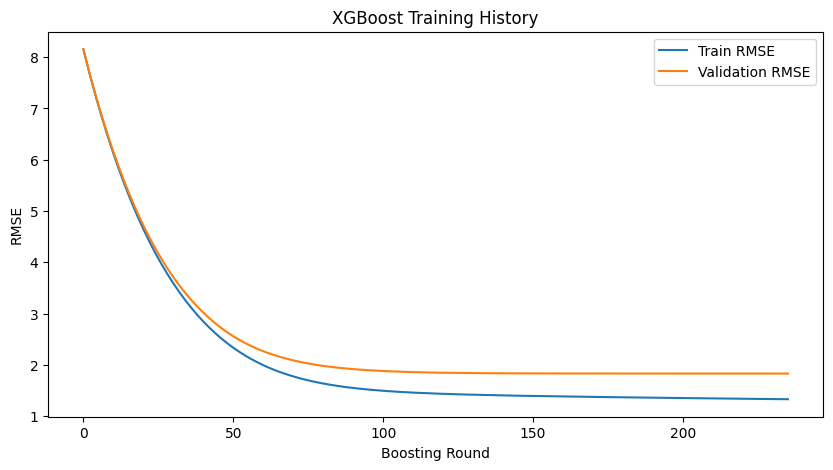

In [147]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_rmse_history,
    label="Train RMSE"
)

plt.plot(
    val_rmse_history,
    label="Validation RMSE"
)

plt.xlabel("Boosting Round")
plt.ylabel("RMSE")
plt.title("XGBoost Training History")
plt.legend()

plt.show()

## 85. Prediction

In [148]:
xgb_train_pred = xgb_model.predict(
    X_train
)

xgb_val_pred = xgb_model.predict(
    X_val
)

xgb_test_pred = xgb_model.predict(
    X_test
)
print(
    "Negative train predictions:",
    (xgb_train_pred < 0).sum()
)

print(
    "Negative validation predictions:",
    (xgb_val_pred < 0).sum()
)

print(
    "Negative test predictions:",
    (xgb_test_pred < 0).sum()
)

Negative train predictions: 28707
Negative validation predictions: 150
Negative test predictions: 29499


## 86. Hàm đánh giá

In [149]:
def regression_metrics(name,y_true,y_pred,mask=None,scope='Completed panel'):
    y_true=np.asarray(y_true,dtype=np.float64).reshape(-1)
    y_pred=np.asarray(y_pred,dtype=np.float64).reshape(-1)
    if len(y_true)!=len(y_pred): raise ValueError('y_true/y_pred khác số mẫu.')
    keep=np.isfinite(y_true)&np.isfinite(y_pred)
    if mask is not None:
        mask=np.asarray(mask,dtype=bool).reshape(-1)
        if len(mask)!=len(y_true): raise ValueError('Mask khác số mẫu.')
        keep &= mask
    y,p=y_true[keep],y_pred[keep]
    if not len(y):
        return pd.DataFrame([dict(Model=name,Scope=scope,N=0,RMSE=np.nan,NRMSE=np.nan,MAE=np.nan,**{'MAPE (%)':np.nan,'MAPE_y_ge_1 (%)':np.nan},R2=np.nan,N_MAPE=0)])
    rmse=float(np.sqrt(mean_squared_error(y,p)))
    nz=np.abs(y)>1e-6
    high=y>=1.0
    return pd.DataFrame([{'Model':name,'Scope':scope,'N':len(y),'RMSE':rmse,
      'NRMSE':rmse/np.ptp(y) if np.ptp(y)>0 else np.nan,'MAE':mean_absolute_error(y,p),
      'MAPE (%)':np.mean(np.abs((y[nz]-p[nz])/y[nz]))*100 if nz.any() else np.nan,
      'MAPE_y_ge_1 (%)':np.mean(np.abs((y[high]-p[high])/y[high]))*100 if high.any() else np.nan,
      'R2':r2_score(y,p) if len(y)>1 else np.nan,'N_MAPE':int(nz.sum())}])

## 87. Đánh giá Train / Validation / Test

In [150]:
xgb_train_metrics = regression_metrics(
    "XGBoost Train",
    y_train,
    xgb_train_pred
)

xgb_val_metrics = regression_metrics(
    "XGBoost Validation",
    y_val,
    xgb_val_pred
)

xgb_test_metrics = regression_metrics(
    "XGBoost Test",
    y_test,
    xgb_test_pred
)

# ghép
xgb_results = pd.concat(
    [
        xgb_train_metrics,
        xgb_val_metrics,
        xgb_test_metrics
    ],
    ignore_index=True
)

xgb_results

,Model,Scope,N,RMSE,NRMSE,MAE,MAPE (%),MAPE_y_ge_1 (%),R2,N_MAPE
0,XGBoost Train,Completed panel,1497130,1.332464,0.013430,0.387639,26.242434,15.969315,0.974799,705647
1,XGBoost Validation,Completed panel,278082,1.832181,0.018507,0.503546,26.963642,19.777460,0.952305,125518
2,XGBoost Test,Completed panel,584346,1.741465,0.018350,0.500897,23.201964,16.123587,0.969276,304616


## 88. Feature Importance

In [151]:
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance":
        xgb_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance

,Feature,Importance
0,PV_lag_1,0.587202
1,PV_mean_1h,0.304567
2,PV_lag_2,0.063953
3,GHI_15min,0.005984
4,Hour_sin,0.004596
5,Hour,0.003581
6,PV_change_15min,0.002335
7,PV_std_2d,0.002319
8,PV_std_4h,0.002290
9,PV_lag_96,0.002142


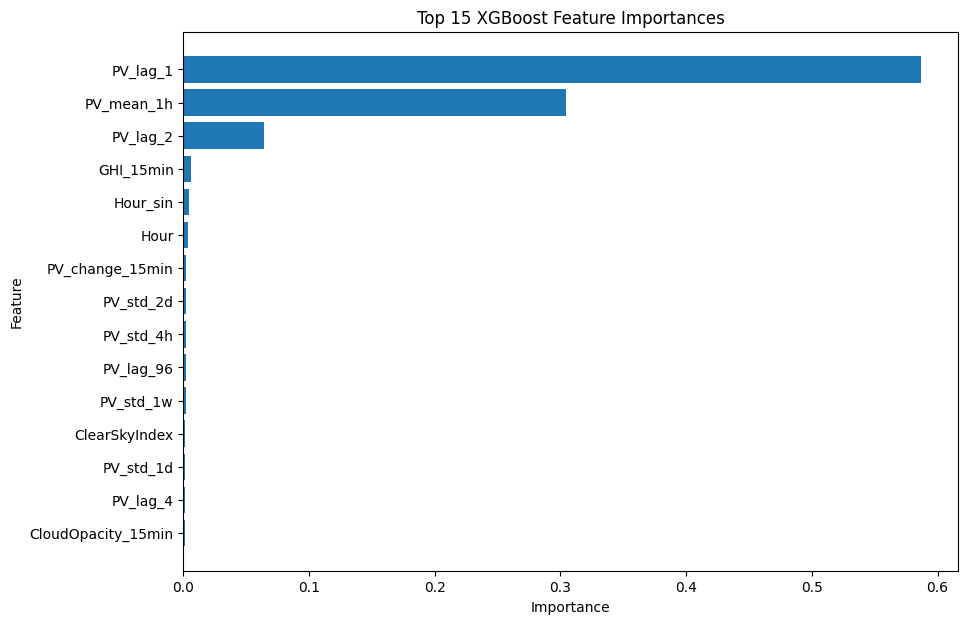

In [152]:
# vẽ top 15 
top15 = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top15["Feature"][::-1],
    top15["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 XGBoost Feature Importances"
)

plt.show()

## 89. Actual vs Prediction trên Test

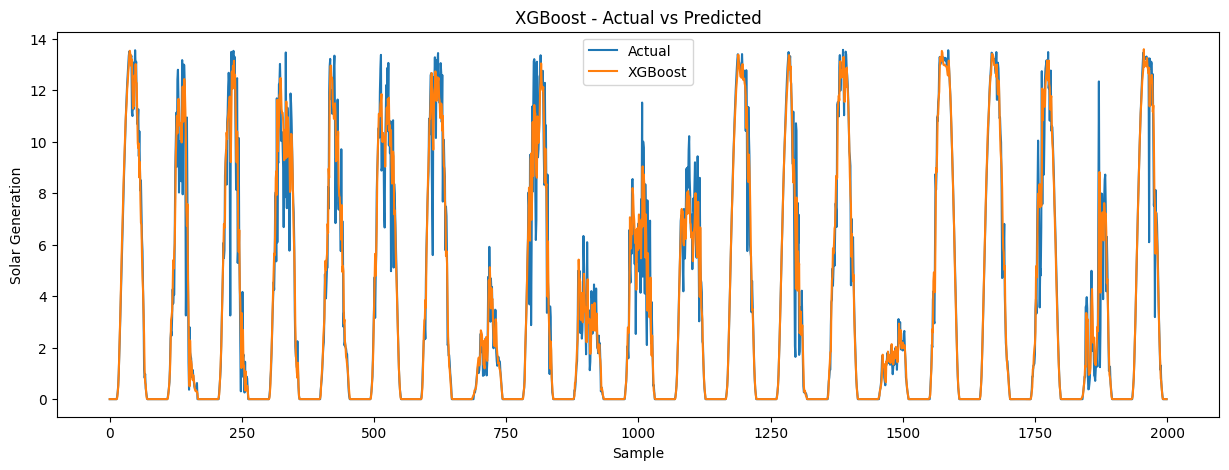

In [153]:
n_plot = min(
    2000,
    len(y_test)
)

plt.figure(figsize=(15, 5))

plt.plot(
    np.asarray(y_test)[:n_plot],
    label="Actual"
)

plt.plot(
    xgb_test_pred[:n_plot],
    label="XGBoost"
)

plt.xlabel("Sample")
plt.ylabel("Solar Generation")
plt.title(
    "XGBoost - Actual vs Predicted"
)

plt.legend()

plt.show()

## 90. Tạo residual cho LSTM

In [154]:
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["XGB_Pred"] = (
    xgb_train_pred.astype("float32")
)

val_df["XGB_Pred"] = (
    xgb_val_pred.astype("float32")
)

test_df["XGB_Pred"] = (
    xgb_test_pred.astype("float32")
)

# residual
train_df["Residual"] = (
    train_df["SolarGeneration"]
    -
    train_df["XGB_Pred"]
).astype("float32")

val_df["Residual"] = (
    val_df["SolarGeneration"]
    -
    val_df["XGB_Pred"]
).astype("float32")

test_df["Residual"] = (
    test_df["SolarGeneration"]
    -
    test_df["XGB_Pred"]
).astype("float32")

print(
    train_df["Residual"].describe()
)

count    1.497130e+06
mean     3.406661e-05
std      1.331352e+00
min     -6.037437e+01
25%     -1.428416e-02
50%     -3.570011e-03
75%      2.376710e-04
max      4.733953e+01
Name: Residual, dtype: float64


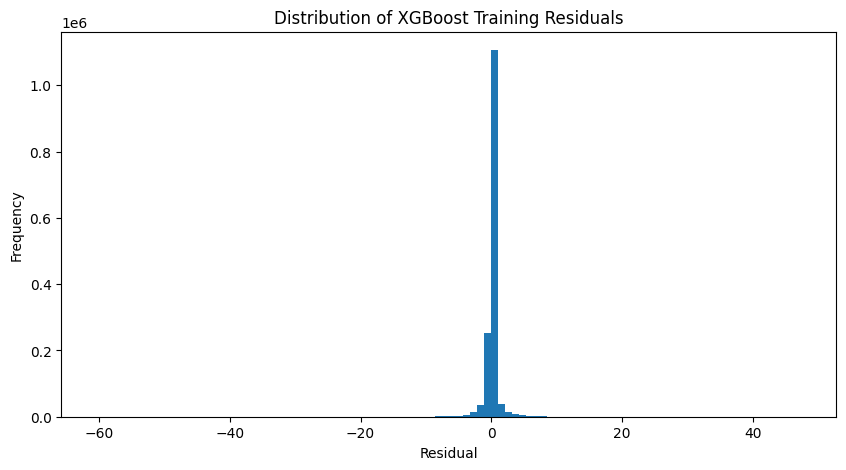

In [155]:
#Kiểm tra residual có centered quanh 0 không
plt.figure(figsize=(10, 5))

plt.hist(
    train_df["Residual"],
    bins=100
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(
    "Distribution of XGBoost Training Residuals"
)

plt.show()

## 91. Import TensorFlow

In [156]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)

## 92.Sắp xếp residual theo từng site

In [157]:
train_df = (
    train_df
    .sort_values(["SiteID", "Timestamp_UTC"])
    .reset_index(drop=True)
)

val_df = (
    val_df
    .sort_values(["SiteID", "Timestamp_UTC"])
    .reset_index(drop=True)
)

test_df = (
    test_df
    .sort_values(["SiteID", "Timestamp_UTC"])
    .reset_index(drop=True)
)

## 93. Tạo sequence residual 24 bước

In [158]:
LOOKBACK = 24

def create_residual_sequences(df, lookback=24):

    X_seq = []
    y_seq = []

    xgb_current = []
    y_current = []

    site_current = []
    time_current = []

    for site_id, group in df.groupby("SiteID"):

        group = (
            group
            .sort_values("Timestamp_UTC")
            .reset_index(drop=True)
        )

        residuals = (
            group["Residual"]
            .to_numpy(dtype=np.float32)
        )

        xgb_pred = (
            group["XGB_Pred"]
            .to_numpy(dtype=np.float32)
        )

        actual = (
            group["SolarGeneration"]
            .to_numpy(dtype=np.float32)
        )

        timestamps = (
            group["Timestamp_UTC"]
            .to_numpy()
        )

        for i in range(
            lookback,
            len(group)
        ):

            X_seq.append(
                residuals[
                    i-lookback:i
                ]
            )

            y_seq.append(
                residuals[i]
            )

            xgb_current.append(
                xgb_pred[i]
            )

            y_current.append(
                actual[i]
            )

            site_current.append(
                site_id
            )

            time_current.append(
                timestamps[i]
            )

    X_seq = np.array(
        X_seq,
        dtype=np.float32
    )

    y_seq = np.array(
        y_seq,
        dtype=np.float32
    )

    X_seq = X_seq.reshape(
        X_seq.shape[0],
        X_seq.shape[1],
        1
    )

    return (
        X_seq,
        y_seq,
        np.array(xgb_current),
        np.array(y_current),
        np.array(site_current),
        np.array(time_current)
    )

## 94. Tạo Train / Validation / Test sequences

In [159]:
(
    X_train_seq,
    y_train_res,
    xgb_train_aligned,
    y_train_aligned,
    site_train_seq,
    time_train_seq
) = create_residual_sequences(
    train_df,
    LOOKBACK
)

(
    X_val_seq,
    y_val_res,
    xgb_val_aligned,
    y_val_aligned,
    site_val_seq,
    time_val_seq
) = create_residual_sequences(
    val_df,
    LOOKBACK
)

(
    X_test_seq,
    y_test_res,
    xgb_test_aligned,
    y_test_aligned,
    site_test_seq,
    time_test_seq
) = create_residual_sequences(
    test_df,
    LOOKBACK
)

print("Train:", X_train_seq.shape)
print("Validation:", X_val_seq.shape)
print("Test:", X_test_seq.shape)

Train: (1496122, 24, 1)
Validation: (277074, 24, 1)
Test: (583338, 24, 1)


## 95. Heteroscedastic loss  

In [160]:
def heteroscedastic_loss(y_true,y_pred):
    y_true=tf.reshape(tf.cast(y_true,y_pred.dtype),(-1,))
    delta=tf.reshape(y_pred[:,0],(-1,))
    log_var=tf.clip_by_value(tf.reshape(y_pred[:,1],(-1,)),-10.0,10.0)
    tf.debugging.assert_equal(tf.shape(y_true),tf.shape(delta))
    return tf.reduce_mean(0.5*tf.exp(-log_var)*tf.square(y_true-delta)+0.5*log_var)

In [161]:
tf.keras.utils.set_random_seed(42)

## 96. Tạo Residual LSTM

In [162]:
residual_lstm = Sequential([
    
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, 1)
    ),

    LSTM(
        64
    ),

    Dense(2)
])

I0000 00:00:1793417480.879248      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793417480.885110      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [163]:
residual_lstm.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss=heteroscedastic_loss
)

residual_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,050 (195.51 KB)

 Trainable params: 50,050 (195.51 KB)

 Non-trainable params: 0 (0.00 B)

## 97. Train 25 epochs

In [164]:
history = residual_lstm.fit(
    X_train_seq,
    y_train_res,

    validation_data=(
        X_val_seq,
        y_val_res
    ),

    epochs=25,
    batch_size=128,

    verbose=1
)

Epoch 1/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 95s 8ms/step - loss: -0.9549 - val_loss: -1.5517
Epoch 2/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 97s 8ms/step - loss: -1.4970 - val_loss: -1.7733
Epoch 3/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 100s 9ms/step - loss: -1.4293 - val_loss: -1.8588
Epoch 4/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 99s 8ms/step - loss: -1.5158 - val_loss: -1.8520
Epoch 5/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 95s 8ms/step - loss: -1.5287 - val_loss: -1.8571
Epoch 6/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 96s 8ms/step - loss: -1.5873 - val_loss: -1.8283
Epoch 7/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 98s 8ms/step - loss: -1.5596 - val_loss: -1.8595
Epoch 8/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 98s 8ms/step - loss: -1.6824 - val_loss: -1.8852
Epoch 9/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 97s 8ms/step - loss: -1.8218 - val_loss: -1.8926
Epoch 10/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 98s 8ms/step - loss: -1.7376 - val_loss: -1.8835
Epoch 11/25
11689/11689 ━━━━━━━━━━━━━━━━━━━━ 95s 8ms/step - loss: -1

## 98. Vẽ loss

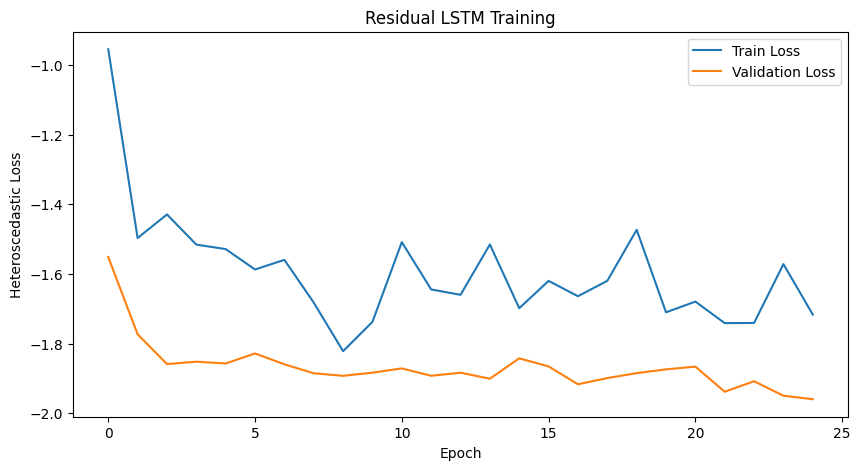

In [165]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Heteroscedastic Loss")
plt.title("Residual LSTM Training")
plt.legend()

plt.show()

## 99. Predict residual + uncertainty

In [166]:
test_out=residual_lstm.predict(X_test_seq,batch_size=128)
delta_test=test_out[:,0]
log_var_test=np.clip(test_out[:,1],-10.0,10.0)
sigma_test=np.exp(0.5*log_var_test)
print('Delta mean:',delta_test.mean(),'| Sigma mean:',sigma_test.mean())

4558/4558 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
Delta mean: 0.0050483057 | Sigma mean: 0.64363885


## 100. Adaptive Hybrid

In [167]:
xgb_base = np.clip(
    xgb_test_aligned,
    0,
    None
)

weight_test = (
    1.0
    /
    (1.0 + sigma_test)
)

correction_limit = (
    0.5 * xgb_base
)

delta_clipped = np.clip(
    delta_test,
    -correction_limit,
    correction_limit
)

hybrid_test_pred = (
    xgb_base
    +
    weight_test
    * delta_clipped
)

hybrid_test_pred = np.clip(
    hybrid_test_pred,
    0,
    None
)

## 101. Đánh giá Hybrid

In [168]:
def aligned_audit(df,sites,times):
    base=df.set_index(['SiteID','Timestamp_UTC'])
    keys=pd.MultiIndex.from_arrays([np.asarray(sites).astype(str),pd.to_datetime(times,utc=True)],names=['SiteID','Timestamp_UTC'])
    audit=base[['SolarObservedValid','Night','DataStatus','ImputationSource']].reindex(keys)
    if audit.isna().any().any(): raise ValueError('Không ghép được cờ chất lượng cho toàn bộ sequence.')
    return audit.reset_index()

audit_test=aligned_audit(test_df,site_test_seq,time_test_seq)
audit_val=aligned_audit(val_df,site_val_seq,time_val_seq)
EVAL_MASK_TEST=(audit_test['SolarObservedValid']&audit_test['DataStatus']).to_numpy(dtype=bool)
EVAL_MASK_VAL=(audit_val['SolarObservedValid']&audit_val['DataStatus']).to_numpy(dtype=bool)
eval_scopes={
 'Observed valid':EVAL_MASK_TEST,
 'Observed valid daylight':EVAL_MASK_TEST&audit_test['Night'].eq(0).to_numpy(),
 'Completed panel':np.ones(len(y_test_aligned),dtype=bool)}
point_results=pd.concat([
 regression_metrics(name,y_test_aligned,pred,mask,scope)
 for scope,mask in eval_scopes.items()
 for name,pred in [('XGBoost aligned',xgb_base),('Hybrid XGBoost-LSTM',hybrid_test_pred)]
],ignore_index=True)
comparison=point_results
hybrid_test_metrics=point_results.loc[point_results.Model.eq('Hybrid XGBoost-LSTM')]
xgb_aligned_metrics=point_results.loc[point_results.Model.eq('XGBoost aligned')]
display(point_results)
print('Bảng chính: Observed valid; bảng phụ: Completed panel. Không mặc định cùng mẫu với bài báo.')

,Model,Scope,N,RMSE,NRMSE,MAE,MAPE (%),MAPE_y_ge_1 (%),R2,N_MAPE
0,XGBoost aligned,Observed valid,281281,2.478342,0.026750,0.988163,22.220813,16.946544,0.960058,281281
1,Hybrid XGBoost-LSTM,Observed valid,281281,2.476556,0.026731,0.981648,21.797595,16.793840,0.960116,281281
2,XGBoost aligned,Observed valid daylight,276532,2.499395,0.026977,1.003191,21.909870,16.935677,0.959805,276532
3,Hybrid XGBoost-LSTM,Observed valid daylight,276532,2.497592,0.026958,0.996543,21.464285,16.782309,0.959863,276532
4,XGBoost aligned,Completed panel,583338,1.742941,0.018366,0.501554,23.208928,16.129773,0.969266,304238
5,Hybrid XGBoost-LSTM,Completed panel,583338,1.741660,0.018352,0.497735,22.447311,15.982598,0.969312,304238


Bảng chính: Observed valid; bảng phụ: Completed panel. Không mặc định cùng mẫu với bài báo.


## 101. Tạo Hybrid prediction cho Validation

In [169]:
val_out=residual_lstm.predict(X_val_seq,batch_size=128)
delta_val=val_out[:,0]
log_var_val=np.clip(val_out[:,1],-10.0,10.0)
sigma_val=np.exp(0.5*log_var_val)
xgb_val_base=np.clip(xgb_val_aligned,0,None)
weight_val=1/(1+sigma_val)
hybrid_val_pred=np.clip(xgb_val_base+weight_val*np.clip(delta_val,-0.5*xgb_val_base,0.5*xgb_val_base),0,None)

2165/2165 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


## 102. Hàm đánh giá Prediction Interval

In [170]:
def interval_metrics(y_true,lower,upper,mask=None):
    y=np.asarray(y_true,dtype=float).reshape(-1)
    lower=np.asarray(lower,dtype=float).reshape(-1); upper=np.asarray(upper,dtype=float).reshape(-1)
    if not (len(y)==len(lower)==len(upper)): raise ValueError('Các mảng interval khác số mẫu.')
    if mask is None: mask=EVAL_MASK_TEST
    keep=np.asarray(mask,dtype=bool)&np.isfinite(y)&np.isfinite(lower)&np.isfinite(upper)
    if not keep.any(): raise ValueError('Không có số đo hợp lệ để đánh giá interval.')
    if (lower[keep]>upper[keep]).any(): raise ValueError('Cận dưới lớn hơn cận trên.')
    return np.mean((y[keep]>=lower[keep])&(y[keep]<=upper[keep])),np.mean(upper[keep]-lower[keep])

## 103. Gaussian interval

In [171]:
gaussian_lower = (
    hybrid_test_pred
    -
    1.96 * sigma_test
)

gaussian_upper = (
    hybrid_test_pred
    +
    1.96 * sigma_test
)

gaussian_picp, gaussian_mpiw = (
    interval_metrics(
        y_test_aligned,
        gaussian_lower,
        gaussian_upper
    )
)

print("Gaussian PICP:", gaussian_picp)
print("Gaussian MPIW:", gaussian_mpiw)

Gaussian PICP: 0.9292486872558047
Gaussian MPIW: 4.840637884217162


## 104. Tìm T tối ưu trên Validation

In [172]:
from scipy.optimize import minimize_scalar
val_error=(y_val_aligned-hybrid_val_pred)[EVAL_MASK_VAL].astype('float64')
sigma_val_safe=np.maximum(sigma_val[EVAL_MASK_VAL].astype('float64'),1e-6)
if not len(val_error): raise ValueError('Validation không có số đo thật.')
def temperature_nll(T):
    s=T*sigma_val_safe
    return np.mean(np.log(s)+0.5*(val_error/s)**2)
temperature_result=minimize_scalar(temperature_nll,bounds=(0.05,10.0),method='bounded')
T_star=float(temperature_result.x)
print('T từ observed validation:',T_star)

T từ observed validation: 1.1899979523053916


## 105. Monte Carlo M=20

In [173]:
M = 20

rng = np.random.default_rng(42)

epsilon = rng.standard_normal(
    size=(
        M,
        len(hybrid_test_pred)
    )
).astype("float32")

mc_samples = (
    hybrid_test_pred[
        None, :
    ]
    +
    T_star
    * sigma_test[
        None, :
    ]
    * epsilon
).astype("float32")

print(
    "MC samples shape:",
    mc_samples.shape
)

MC samples shape: (20, 583338)


## 106. MC 95% interval

In [174]:
mc_lower = np.quantile(
    mc_samples,
    0.025,
    axis=0
)

mc_upper = np.quantile(
    mc_samples,
    0.975,
    axis=0
)
mc_picp, mc_mpiw = (
    interval_metrics(
        y_test_aligned,
        mc_lower,
        mc_upper
    )
)

print("MC PICP:", mc_picp)
print("MC MPIW:", mc_mpiw)

MC PICP: 0.9139437075380136
MC MPIW: 4.84000981447734


## 107. Calibration residual

In [175]:
conformal_errors=np.abs(y_val_aligned-hybrid_val_pred)[EVAL_MASK_VAL].astype('float64')
alpha=0.05
# Theo biểu thức của bài báo: Q_(1-alpha/2) trên SAI SỐ TUYỆT ĐỐI.
q_conformal=float(np.quantile(conformal_errors,1-alpha/2))
# Bổ sung, KHÔNG thay âm thầm công thức tác giả: split conformal chuẩn trên |error|.
n_cal=len(conformal_errors)
if n_cal<20: raise ValueError('Cần ít nhất 20 mẫu calibration cho mức 95%.')
rank=int(np.ceil((n_cal+1)*(1-alpha)))
if rank>n_cal: raise ValueError('Calibration chưa đủ cho alpha đã chọn.')
q_conformal_standard=float(np.partition(conformal_errors,rank-1)[rank-1])
print('q paper convention:',q_conformal,'| q split-conformal 95%:',q_conformal_standard)
# Dữ liệu chuỗi thời gian không exchangeable nói chung; không tuyên bố bảo đảm coverage hữu hạn mẫu ở đây.

q paper convention: 7.282675170898445 | q split-conformal 95%: 4.5475311279296875


## 108. Conformal interval

In [176]:
conformal_lower = (
    hybrid_test_pred
    -
    q_conformal
)

conformal_upper = (
    hybrid_test_pred
    +
    q_conformal
)
conformal_picp, conformal_mpiw = (
    interval_metrics(
        y_test_aligned,
        conformal_lower,
        conformal_upper
    )
)

print(
    "Conformal PICP:",
    conformal_picp
)

print(
    "Conformal MPIW:",
    conformal_mpiw
)

Conformal PICP: 0.9799808732193074
Conformal MPIW: 14.565350577510538


## 109. CRPS cho Gaussian

In [177]:
from scipy.stats import norm
def gaussian_crps(
    y,
    mu,
    sigma
):
    sigma = np.maximum(
        sigma,
        1e-6
    )

    z = (
        (y - mu)
        / sigma
    )


    crps = sigma * (
        z * (
            2 * norm.cdf(z) - 1
        )
        +
        2 * norm.pdf(z)
        -
        1 / np.sqrt(np.pi)
    )

    return np.mean(crps)

gaussian_crps_value = gaussian_crps(
    np.asarray(y_test_aligned)[EVAL_MASK_TEST],
    hybrid_test_pred[EVAL_MASK_TEST],
    sigma_test[EVAL_MASK_TEST]
)

print(
    "Gaussian CRPS:",
    gaussian_crps_value
)

Gaussian CRPS: 0.7354357135266107


## 110. CRPS cho MC Ensemble

In [178]:
def ensemble_crps(
    y_true,
    samples
):
    y_true = np.asarray(
        y_true,
        dtype=np.float32
    )

    M = samples.shape[0]

    term1 = np.mean(
        np.abs(
            samples
            -
            y_true[None, :]
        ),
        axis=0
    )

    sorted_samples = np.sort(
        samples,
        axis=0
    )

    j = np.arange(
        1,
        M + 1,
        dtype=np.float32
    )

    coeff = (
        2 * j
        - M
        - 1
    )[:, None]

    term2 = (
        np.sum(
            coeff
            * sorted_samples,
            axis=0
        )
        /
        (M ** 2)
    )

    return np.mean(
        term1 - term2
    )

mc_crps_value = ensemble_crps(
    y_test_aligned[EVAL_MASK_TEST],
    mc_samples[:, EVAL_MASK_TEST]
)

print(
    "MC CRPS:",
    mc_crps_value
)

MC CRPS: 0.7875337


## 111. Pinball Loss

In [179]:
def pinball_loss(
    y_true,
    y_pred_quantile,
    tau
):
    error = (
        y_true
        -
        y_pred_quantile
    )

    return np.mean(
        np.maximum(
            tau * error,
            (tau - 1) * error
        )
    )

# GAUSSIAN
gaussian_pinball = (
    pinball_loss(
        np.asarray(y_test_aligned)[EVAL_MASK_TEST],
        gaussian_lower[EVAL_MASK_TEST],
        0.025
    )
    +
    pinball_loss(
        np.asarray(y_test_aligned)[EVAL_MASK_TEST],
        gaussian_upper[EVAL_MASK_TEST],
        0.975
    )
) / 2

# MC
mc_pinball = (
    pinball_loss(
        np.asarray(y_test_aligned)[EVAL_MASK_TEST],
        mc_lower[EVAL_MASK_TEST],
        0.025
    )
    +
    pinball_loss(
        np.asarray(y_test_aligned)[EVAL_MASK_TEST],
        mc_upper[EVAL_MASK_TEST],
        0.975
    )
) / 2

## 112. Bảng kết quả Uncertainty

In [180]:
standard_lower=hybrid_test_pred-q_conformal_standard
standard_upper=hybrid_test_pred+q_conformal_standard
standard_picp,standard_mpiw=interval_metrics(y_test_aligned,standard_lower,standard_upper)
uncertainty_results=pd.DataFrame({
 'Method':['Gaussian (Uncalibrated)','MC Ensemble (Calibrated)','Conformal (paper Q97.5 abs-error)','Split conformal (Q95 finite sample)'],
 'Scope':['Observed valid']*4,'N':[int(EVAL_MASK_TEST.sum())]*4,
 'PICP':[gaussian_picp,mc_picp,conformal_picp,standard_picp],
 'MPIW':[gaussian_mpiw,mc_mpiw,conformal_mpiw,standard_mpiw],
 'CRPS':[gaussian_crps_value,mc_crps_value,np.nan,np.nan],
 'Pinball Loss':[gaussian_pinball,mc_pinball,np.nan,np.nan]})
display(uncertainty_results)

,Method,Scope,N,PICP,MPIW,CRPS,Pinball Loss
0,Gaussian (Uncalibrated),Observed valid,281281,0.929249,4.840638,0.735436,0.105338
1,MC Ensemble (Calibrated),Observed valid,281281,0.913944,4.840010,0.787534,0.114220
2,Conformal (paper Q97.5 abs-error),Observed valid,281281,0.979981,14.565351,NaN,NaN
3,Split conformal (Q95 finite sample),Observed valid,281281,0.958220,9.095062,NaN,NaN


## 113. Vẽ Prediction Interval

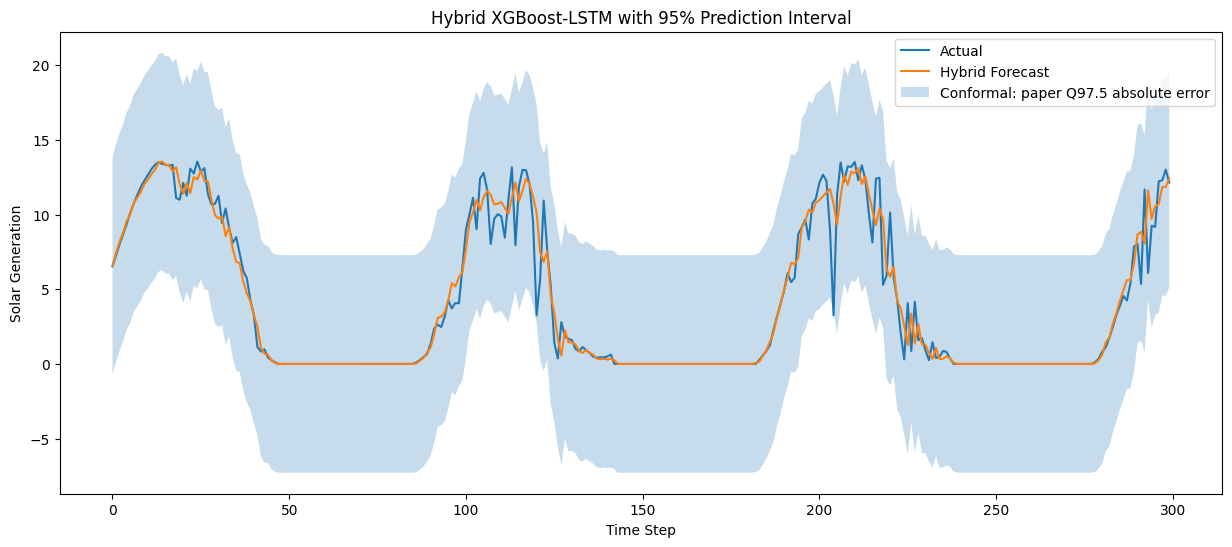

In [181]:
n_plot = 300

x_plot = np.arange(
    n_plot
)

plt.figure(
    figsize=(15, 6)
)

plt.plot(
    x_plot,
    y_test_aligned[:n_plot],
    label="Actual"
)

plt.plot(
    x_plot,
    hybrid_test_pred[:n_plot],
    label="Hybrid Forecast"
)

plt.fill_between(
    x_plot,
    conformal_lower[:n_plot],
    conformal_upper[:n_plot],
    alpha=0.25,
    label="Conformal: paper Q97.5 absolute error"
)

plt.xlabel("Time Step")
plt.ylabel("Solar Generation")

plt.title(
    "Hybrid XGBoost-LSTM with 95% Prediction Interval"
)

plt.legend()

plt.show()

## 114. Tạo bảng test đã align với Hybrid

In [182]:
hybrid_eval=pd.DataFrame({'SiteID':site_test_seq.astype(str),'Timestamp_UTC':pd.to_datetime(time_test_seq,utc=True),
 'Actual':y_test_aligned,'XGBoost':xgb_base,'Hybrid':hybrid_test_pred,
 'ObservedValid':EVAL_MASK_TEST,'Night':audit_test['Night'].to_numpy()})
display(hybrid_eval.head())

,SiteID,Timestamp_UTC,Actual,XGBoost,Hybrid,ObservedValid,Night
0,1_14,2021-11-29 21:45:00+00:00,6.531250,6.686917,6.583675,True,0
1,1_14,2021-11-29 22:00:00+00:00,7.281250,7.521263,7.424183,True,0
2,1_14,2021-11-29 22:15:00+00:00,8.023438,8.298844,8.172918,True,0
3,1_14,2021-11-29 22:30:00+00:00,8.679688,8.940872,8.797390,True,0
4,1_14,2021-11-29 22:45:00+00:00,9.359375,9.707894,9.549776,True,0


## 115. Tạo các baseline

In [183]:
baseline_test = (
    test_df[
        [
            "SiteID",
            "Timestamp_UTC",
            "SolarGeneration",
            "GHI_15min",
            "Hour"
        ]
    ]
    .copy()
    .sort_values(
        ["SiteID", "Timestamp_UTC"]
    )
)

In [184]:
# persistence 1h
baseline_test["Persistence_1h"] = (
    baseline_test
    .groupby("SiteID")["SolarGeneration"]
    .shift(4)
)
# persistence 2h
baseline_test["Persistence_24h"] = (
    baseline_test
    .groupby("SiteID")["SolarGeneration"]
    .shift(96)
)
# zezo model
baseline_test["Zero"] = 0.0

## 116. Smart Persistence

In [185]:
baseline_test["GHI_lag_1h"] = (
    baseline_test
    .groupby("SiteID")["GHI_15min"]
    .shift(4)
)

ghi_now = baseline_test["GHI_15min"]
ghi_prev = baseline_test["GHI_lag_1h"]
pv_prev = baseline_test["Persistence_1h"]

baseline_test["Smart_Persistence"] = np.where(
    # Nếu hiện tại gần như không có nắng
    ghi_now <= 5,
    0.0,

    np.where(
        # Nếu cả hiện tại và 1 giờ trước đều có irradiance
        ghi_prev > 5,

        pv_prev * (
            ghi_now / ghi_prev
        ),

        # Không đủ GHI quá khứ → fallback persistence
        pv_prev
    )
)

baseline_test["Smart_Persistence"] = (
    baseline_test["Smart_Persistence"]
    .clip(lower=0)
)

## 117. Climatology chỉ học từ TRAIN

In [186]:
climatology = (
    train_df
    .groupby(
        ["SiteID", "Hour"]
    )["SolarGeneration"]
    .mean()
    .rename("Climatology")
    .reset_index()
)

baseline_test = baseline_test.merge(
    climatology,
    on=["SiteID", "Hour"],
    how="left",
    validate="many_to_one"
)

## 118. Ghép baseline với Hybrid

In [187]:
baseline_compare = hybrid_eval.merge(
    baseline_test[
        [
            "SiteID",
            "Timestamp_UTC",
            "Persistence_1h",
            "Persistence_24h",
            "Smart_Persistence",
            "Zero",
            "Climatology"
        ]
    ],
    on=[
        "SiteID",
        "Timestamp_UTC"
    ],
    how="left"
)
baseline_compare.head()

,SiteID,Timestamp_UTC,Actual,XGBoost,Hybrid,ObservedValid,Night,Persistence_1h,Persistence_24h,Smart_Persistence,Zero,Climatology
0,1_14,2021-11-29 21:45:00+00:00,6.531250,6.686917,6.583675,True,0,3.179688,NaN,4.529649,0.0,2.076283
1,1_14,2021-11-29 22:00:00+00:00,7.281250,7.521263,7.424183,True,0,4.031250,NaN,5.733521,0.0,4.136756
2,1_14,2021-11-29 22:15:00+00:00,8.023438,8.298844,8.172918,True,0,4.882812,NaN,6.629342,0.0,4.136756
3,1_14,2021-11-29 22:30:00+00:00,8.679688,8.940872,8.797390,True,0,5.726562,NaN,7.506066,0.0,4.136756
4,1_14,2021-11-29 22:45:00+00:00,9.359375,9.707894,9.549776,True,0,6.531250,NaN,8.335783,0.0,4.136756


## 119. Dùng cùng sample cho tất cả model

In [188]:
compare_cols = [
    "Actual",
    "XGBoost",
    "Hybrid",
    "Persistence_1h",
    "Persistence_24h",
    "Smart_Persistence",
    "Zero",
    "Climatology"
]

baseline_compare_clean = (
    baseline_compare
    .dropna(
        subset=compare_cols
    )
    .reset_index(drop=True)
)

print(
    "Samples used:",
    len(baseline_compare_clean)
)

Samples used: 580314


## 120. Đánh giá toàn bộ baseline

In [189]:
models_to_evaluate={'Zero Model':'Zero','Persistence (1h)':'Persistence_1h','Smart Persistence':'Smart_Persistence',
 'Persistence (24h)':'Persistence_24h','Climatology':'Climatology','XGBoost':'XGBoost','Hybrid XGBoost-LSTM':'Hybrid'}
rows=[]
for scope,mask in [('Observed valid',baseline_compare_clean['ObservedValid'].to_numpy()),
 ('Observed valid daylight',(baseline_compare_clean['ObservedValid']&baseline_compare_clean['Night'].eq(0)).to_numpy()),
 ('Completed panel',np.ones(len(baseline_compare_clean),dtype=bool))]:
    for name,col in models_to_evaluate.items():
        rows.append(regression_metrics(name,baseline_compare_clean['Actual'],baseline_compare_clean[col],mask,scope))
baseline_results=pd.concat(rows,ignore_index=True)
display(baseline_results.sort_values(['Scope','RMSE']))

,Model,Scope,N,RMSE,NRMSE,MAE,MAPE (%),MAPE_y_ge_1 (%),R2,N_MAPE
20,Hybrid XGBoost-LSTM,Completed panel,580314,1.738373,0.018317,0.497108,22.501303,16.018119,0.969263,302303
19,XGBoost,Completed panel,580314,1.739656,0.018331,0.500919,23.265783,16.165568,0.969218,302303
16,Smart Persistence,Completed panel,580314,3.118942,0.032865,1.005960,44.351403,32.748884,0.901056,302303
15,Persistence (1h),Completed panel,580314,3.856828,0.040640,1.504178,94.911003,52.410878,0.848702,302303
17,Persistence (24h),Completed panel,580314,4.794394,0.050519,1.504712,78.500040,51.668770,0.766202,302303
18,Climatology,Completed panel,580314,4.916804,0.051809,1.940877,95.403026,56.902638,0.754111,302303
14,Zero Model,Completed panel,580314,10.776075,0.113549,4.219865,100.000000,100.000000,-0.181122,302303
6,Hybrid XGBoost-LSTM,Observed valid,279574,2.472968,0.026692,0.981452,21.839763,16.826189,0.960072,279574
5,XGBoost,Observed valid,279574,2.474758,0.026711,0.987954,22.263567,16.979140,0.960015,279574
2,Smart Persistence,Observed valid,279574,4.424499,0.047756,1.990513,45.363411,34.201460,0.872190,279574


## 121. Tính mức cải thiện Hybrid so với XGBoost

In [190]:
for scope,g in baseline_results.groupby('Scope'):
    vals=g.set_index('Model')['RMSE']
    print(scope,': Hybrid giảm RMSE',round(100*(vals['XGBoost']-vals['Hybrid XGBoost-LSTM'])/vals['XGBoost'],3),'%')

Completed panel : Hybrid giảm RMSE 0.074 %
Observed valid : Hybrid giảm RMSE 0.072 %
Observed valid daylight : Hybrid giảm RMSE 0.072 %


In [191]:
from pathlib import Path

C_DIR = Path("/kaggle/working/experiment_C")
C_DIR.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    C_DIR / "baseline_results_C.csv",
    index=False
)

print("Đã lưu kết quả C.")

Đã lưu kết quả C.


## 122. Định nghĩa các nhóm feature

In [192]:
weather_features=['AirTemperature','ApparentTemperature','DewPointTemperature','RelativeHumidity','WindSpeed','WindDir_sin','WindDir_cos','VaporPressure','TempDiff']
cyclical_features=['Hour_sin','Hour_cos','Day_sin','Day_cos']
time_features=['Hour','DayOfYear']+cyclical_features
solar_features=['GHI_15min','GHI_clear','ClearSkyIndex','CloudOpacity_15min','SolarZenith']
lag_features=history_cols

## 123. Tạo các trường hợp ablation

In [193]:
# Các tên nhóm dưới đây áp dụng cho nhánh XGBoost. Mọi biến thể vẫn có lịch sử residual của LSTM.
# Đây là lựa chọn tái dựng, bài báo chưa nêu rõ có bỏ lịch sử ở cả hai nhánh hay không.
ablation_selected={
 'All Features':feature_cols,
 'No Weather':[c for c in feature_cols if c not in weather_features],
 'No Time':[c for c in feature_cols if c not in time_features],
 'No Cyclical':[c for c in feature_cols if c not in cyclical_features],
 'No Solar':[c for c in feature_cols if c not in solar_features],
 'No Lag':[c for c in feature_cols if c not in lag_features],
 'Only Weather':weather_features,
 'Only Time':time_features,
 'Only Lag':lag_features}
assert set(ablation_selected['No Time']) != set(ablation_selected['No Cyclical'])

## 124. Huấn luyện lại XGBoost khi bỏ từng nhóm

In [194]:
def train_hybrid_variant(selected):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    base=XGBRegressor(**xgb_model.get_params())
    base.fit(train_df[selected],train_df['SolarGeneration'],verbose=False)
    blocks=[]
    for frame in [train_df,val_df,test_df]:
        d=frame[['SiteID','Timestamp_UTC','SolarGeneration']].copy()
        d['XGB_Pred']=base.predict(frame[selected]).astype('float32')
        d['Residual']=(d['SolarGeneration']-d['XGB_Pred']).astype('float32')
        blocks.append(create_residual_sequences(d,LOOKBACK))
    tr,va,te=blocks
    # te = Xseq, residual, XGB aligned, actual, SiteID, time
    assert np.array_equal(te[4],site_test_seq)
    assert np.array_equal(pd.to_datetime(te[5],utc=True).asi8,pd.to_datetime(time_test_seq,utc=True).asi8)
    model=Sequential([LSTM(64,return_sequences=True,input_shape=(LOOKBACK,1)),LSTM(64),Dense(2)])
    model.compile(optimizer=Adam(learning_rate=0.001),loss=heteroscedastic_loss)
    model.fit(tr[0],tr[1],validation_data=(va[0],va[1]),epochs=25,batch_size=128,verbose=2)
    out=model.predict(te[0],batch_size=128,verbose=0)
    sigma=np.exp(0.5*np.clip(out[:,1],-10,10))
    b=np.clip(te[2],0,None)
    pred=np.clip(b+np.clip(out[:,0],-0.5*b,0.5*b)/(1+sigma),0,None)
    return te[3],pred

ablation_rows=[]
if RUN_FULL_ABLATION:
    for name,selected in ablation_selected.items():
        print('Hybrid ablation:',name,'| số biến:',len(selected))
        if name=='All Features':
            actual,pred=y_test_aligned,hybrid_test_pred
        else:
            actual,pred=train_hybrid_variant(selected)
        for scope,mask in eval_scopes.items():
            row=regression_metrics(name,actual,pred,mask,scope)
            row['Architecture']='XGBoost + residual LSTM'
            ablation_rows.append(row)
        # Ghi checkpoint sau mỗi trường hợp, có thể đọc kết quả đã hoàn thành.
        pd.concat(ablation_rows,ignore_index=True).to_csv(OUTPUT_DIR/'ablation_partial.csv',index=False)
else:
    print('Chưa chạy ablation. Đặt RUN_FULL_ABLATION=True ở đầu notebook để tái dựng đủ Bảng III.')
ablation_results=pd.concat(ablation_rows,ignore_index=True) if ablation_rows else pd.DataFrame()

Hybrid ablation: All Features | số biến: 37
Hybrid ablation: No Weather | số biến: 28


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
11689/11689 - 81s - 7ms/step - loss: -1.0323e+00 - val_loss: -1.5613e+00
Epoch 2/25
11689/11689 - 80s - 7ms/step - loss: -1.3156e+00 - val_loss: -1.5907e+00
Epoch 3/25
11689/11689 - 79s - 7ms/step - loss: -1.4952e+00 - val_loss: -1.7623e+00
Epoch 4/25
11689/11689 - 79s - 7ms/step - loss: -1.4942e+00 - val_loss: -1.8444e+00
Epoch 5/25
11689/11689 - 79s - 7ms/step - loss: -1.5308e+00 - val_loss: -1.8456e+00
Epoch 6/25
11689/11689 - 79s - 7ms/step - loss: -1.6164e+00 - val_loss: -1.8564e+00
Epoch 7/25
11689/11689 - 78s - 7ms/step - loss: -1.6392e+00 - val_loss: -1.8681e+00
Epoch 8/25
11689/11689 - 78s - 7ms/step - loss: -1.6455e+00 - val_loss: -1.8851e+00
Epoch 9/25
11689/11689 - 78s - 7ms/step - loss: -1.0562e+00 - val_loss: -1.8588e+00
Epoch 10/25
11689/11689 - 78s - 7ms/step - loss: -1.6674e+00 - val_loss: -1.8866e+00
Epoch 11/25
11689/11689 - 78s - 7ms/step - loss: -1.6877e+00 - val_loss: -1.8828e+00
Epoch 12/25
11689/11689 - 78s - 7ms/step - loss: -1.6350e+00 - val_loss: -

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
11689/11689 - 80s - 7ms/step - loss: -1.0153e+00 - val_loss: -1.5851e+00
Epoch 2/25
11689/11689 - 78s - 7ms/step - loss: -1.3689e+00 - val_loss: -1.8168e+00
Epoch 3/25
11689/11689 - 77s - 7ms/step - loss: -1.3965e+00 - val_loss: -1.7723e+00
Epoch 4/25
11689/11689 - 77s - 7ms/step - loss: -1.4712e+00 - val_loss: -1.8438e+00
Epoch 5/25
11689/11689 - 76s - 7ms/step - loss: -1.5684e+00 - val_loss: -1.8306e+00
Epoch 6/25
11689/11689 - 76s - 7ms/step - loss: -1.6278e+00 - val_loss: -1.8629e+00
Epoch 7/25
11689/11689 - 76s - 7ms/step - loss: -1.6913e+00 - val_loss: -1.5488e+00
Epoch 8/25
11689/11689 - 77s - 7ms/step - loss: -1.6215e+00 - val_loss: -1.8400e+00
Epoch 9/25
11689/11689 - 76s - 7ms/step - loss: -1.7274e+00 - val_loss: -1.8474e+00
Epoch 10/25
11689/11689 - 76s - 7ms/step - loss: -1.7384e+00 - val_loss: -1.8656e+00
Epoch 11/25
11689/11689 - 76s - 7ms/step - loss: -1.7438e+00 - val_loss: -1.8740e+00
Epoch 12/25
11689/11689 - 77s - 7ms/step - loss: -1.8242e+00 - val_loss: -

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
11689/11689 - 80s - 7ms/step - loss: -5.0533e-01 - val_loss: -8.9797e-01
Epoch 2/25
11689/11689 - 77s - 7ms/step - loss: -7.0323e-01 - val_loss: -9.1788e-01
Epoch 3/25
11689/11689 - 77s - 7ms/step - loss: -9.2250e-01 - val_loss: -8.8386e-01
Epoch 4/25
11689/11689 - 77s - 7ms/step - loss: -9.5421e-01 - val_loss: -7.2402e-01
Epoch 5/25
11689/11689 - 77s - 7ms/step - loss: -1.0665e+00 - val_loss: -9.4491e-01
Epoch 6/25
11689/11689 - 77s - 7ms/step - loss: -1.0301e+00 - val_loss: -9.5743e-01
Epoch 7/25
11689/11689 - 78s - 7ms/step - loss: -1.1544e+00 - val_loss: -1.1153e+00
Epoch 8/25
11689/11689 - 78s - 7ms/step - loss: -1.0894e+00 - val_loss: -1.1810e+00
Epoch 9/25
11689/11689 - 78s - 7ms/step - loss: -1.1315e+00 - val_loss: -1.2306e+00
Epoch 10/25
11689/11689 - 78s - 7ms/step - loss: -1.2837e+00 - val_loss: -1.1762e+00
Epoch 11/25
11689/11689 - 78s - 7ms/step - loss: -1.3099e+00 - val_loss: -1.4425e+00
Epoch 12/25
11689/11689 - 78s - 7ms/step - loss: -1.4091e+00 - val_loss: -

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
11689/11689 - 80s - 7ms/step - loss: -7.8007e-01 - val_loss: -1.0413e+00
Epoch 2/25
11689/11689 - 77s - 7ms/step - loss: -1.0672e+00 - val_loss: -1.0452e+00
Epoch 3/25
11689/11689 - 77s - 7ms/step - loss: -1.2633e+00 - val_loss: -1.6473e+00
Epoch 4/25
11689/11689 - 77s - 7ms/step - loss: -1.2989e+00 - val_loss: -1.6392e+00
Epoch 5/25
11689/11689 - 77s - 7ms/step - loss: -1.1793e+00 - val_loss: -1.5875e+00
Epoch 6/25
11689/11689 - 77s - 7ms/step - loss: -1.1924e+00 - val_loss: -1.5994e+00
Epoch 7/25
11689/11689 - 77s - 7ms/step - loss: -1.3412e+00 - val_loss: -1.1756e+00
Epoch 8/25
11689/11689 - 77s - 7ms/step - loss: -1.2279e+00 - val_loss: -1.6429e+00
Epoch 9/25
11689/11689 - 78s - 7ms/step - loss: -1.1183e+00 - val_loss: -1.5496e+00
Epoch 10/25
11689/11689 - 77s - 7ms/step - loss: -1.4162e+00 - val_loss: -1.6364e+00
Epoch 11/25
11689/11689 - 77s - 7ms/step - loss: -1.4625e+00 - val_loss: -1.7442e+00
Epoch 12/25
11689/11689 - 77s - 7ms/step - loss: -1.1825e+00 - val_loss: -

## 125. Tính mức suy giảm khi bỏ feature

In [195]:
if not ablation_results.empty:
    references=ablation_results.loc[ablation_results.Model.eq('All Features')].set_index('Scope')['RMSE']
    ablation_results['Delta_RMSE_%']=100*(ablation_results['RMSE']/ablation_results['Scope'].map(references)-1)
    display(ablation_results.sort_values(['Scope','RMSE']))

,Model,Scope,N,RMSE,NRMSE,MAE,MAPE (%),MAPE_y_ge_1 (%),R2,N_MAPE,Architecture,Delta_RMSE_%
11,No Cyclical,Completed panel,583338,1.741547,0.018351,0.496102,22.245826,15.951624,0.969316,304238,XGBoost + residual LSTM,-0.006507
2,All Features,Completed panel,583338,1.741660,0.018352,0.497735,22.447311,15.982598,0.969312,304238,XGBoost + residual LSTM,0.000000
8,No Time,Completed panel,583338,1.742626,0.018362,0.498427,22.547538,16.075894,0.969278,304238,XGBoost + residual LSTM,0.055466
5,No Weather,Completed panel,583338,1.743200,0.018368,0.496326,22.403640,15.988213,0.969257,304238,XGBoost + residual LSTM,0.088377
14,No Solar,Completed panel,583338,1.892292,0.019939,0.544918,23.940700,17.333364,0.963774,304238,XGBoost + residual LSTM,8.648722
26,Only Lag,Completed panel,583338,1.925808,0.020292,0.554673,24.399163,17.613453,0.962479,304238,XGBoost + residual LSTM,10.573097
23,Only Time,Completed panel,583338,8.004896,0.084348,2.607839,171.729125,88.394357,0.351727,304238,XGBoost + residual LSTM,359.612927
20,Only Weather,Completed panel,583338,8.651603,0.091163,4.040922,347.150245,103.110384,0.242749,304238,XGBoost + residual LSTM,396.744548
17,No Lag,Completed panel,583338,8.742230,0.092118,3.255232,184.758141,133.107409,0.226801,304238,XGBoost + residual LSTM,401.948021
0,All Features,Observed valid,281281,2.476556,0.026731,0.981648,21.797595,16.793840,0.960116,281281,XGBoost + residual LSTM,0.000000


## 127. Tính lại bảng cuối

In [196]:
if not ablation_results.empty:
    display(ablation_results.sort_values(['Scope','RMSE']))

,Model,Scope,N,RMSE,NRMSE,MAE,MAPE (%),MAPE_y_ge_1 (%),R2,N_MAPE,Architecture,Delta_RMSE_%
11,No Cyclical,Completed panel,583338,1.741547,0.018351,0.496102,22.245826,15.951624,0.969316,304238,XGBoost + residual LSTM,-0.006507
2,All Features,Completed panel,583338,1.741660,0.018352,0.497735,22.447311,15.982598,0.969312,304238,XGBoost + residual LSTM,0.000000
8,No Time,Completed panel,583338,1.742626,0.018362,0.498427,22.547538,16.075894,0.969278,304238,XGBoost + residual LSTM,0.055466
5,No Weather,Completed panel,583338,1.743200,0.018368,0.496326,22.403640,15.988213,0.969257,304238,XGBoost + residual LSTM,0.088377
14,No Solar,Completed panel,583338,1.892292,0.019939,0.544918,23.940700,17.333364,0.963774,304238,XGBoost + residual LSTM,8.648722
26,Only Lag,Completed panel,583338,1.925808,0.020292,0.554673,24.399163,17.613453,0.962479,304238,XGBoost + residual LSTM,10.573097
23,Only Time,Completed panel,583338,8.004896,0.084348,2.607839,171.729125,88.394357,0.351727,304238,XGBoost + residual LSTM,359.612927
20,Only Weather,Completed panel,583338,8.651603,0.091163,4.040922,347.150245,103.110384,0.242749,304238,XGBoost + residual LSTM,396.744548
17,No Lag,Completed panel,583338,8.742230,0.092118,3.255232,184.758141,133.107409,0.226801,304238,XGBoost + residual LSTM,401.948021
0,All Features,Observed valid,281281,2.476556,0.026731,0.981648,21.797595,16.793840,0.960116,281281,XGBoost + residual LSTM,0.000000


In [197]:
import importlib.metadata as md
import sys
def package_version(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return getattr(sys.modules.get(name),'__version__','distribution metadata unavailable')
paper_point=pd.DataFrame([
 {'Model':'XGBoost aligned','Paper_RMSE':2.8123,'Paper_MAE':1.0319,'Paper_MAPE':28.12,'Paper_R2':0.9215},
 {'Model':'Hybrid XGBoost-LSTM','Paper_RMSE':2.5728,'Paper_MAE':0.6394,'Paper_MAPE':13.68,'Paper_R2':0.9343}])
paper_comparison=point_results.merge(paper_point,on='Model',how='left')
paper_comparison['RMSE_delta_percent']=100*(paper_comparison['RMSE']/paper_comparison['Paper_RMSE']-1)
paper_comparison['MAPE_delta_points']=paper_comparison['MAPE (%)']-paper_comparison['Paper_MAPE']
paper_comparison['Comparable_test_protocol']=False
for name,frame in {'point_results':point_results,'baseline_results':baseline_results,
 'ablation_results':ablation_results,'uncertainty_results':uncertainty_results,'paper_comparison':paper_comparison,
 'predictions_aligned':hybrid_eval}.items():
    frame.to_csv(OUTPUT_DIR/f'{name}.csv',index=False)
notes={
 'experiment':'Offline paper reconstruction; contemporaneous weather/GHI; rolling observed past, not fixed-origin multi-step forecasting.',
 'split':'Each gap=5% unique timestamps; remaining timeline 60/20/20. Not necessarily 60/20/20 rows.',
 'fit_rule':'Weather/PV imputers and all median fallbacks fit TRAIN only.',
 'evaluation':'Primary: observed valid original targets; completed panel separately. Calibration: observed valid VAL.',
 'GHI':'Retains paper-style bidirectional clear-sky-index interpolation: offline, not causal real-time inputs.',
 'unknown_paper_choices':['Exact split dates','Imputer hyperparameters','Complete predictor lists and feature-group definitions','Zero handling in MAPE','NRMSE denominator','Pinball quantile aggregation','Quality thresholds and capacity units'],
 'implementation_choices':{'weather_forward_fill_steps':4,'imputer_max_iter':10,'min_observed_train_for_site_imputer':50,'MAPE_exclusion_epsilon':1e-6,'NRMSE':'test subset range','std_ddof':0,'extra_time_features':['Hour','DayOfYear'],'capacity_rule':'audit only; not enforced','conformal':'paper Q97.5 absolute error plus separate finite-sample Q95'},
 'limitations':['No DNI/DHI/pressure/elevation columns supplied','No complete author-cleaned output comparison in this notebook','No claim of exact numeric reproduction or finite-sample time-series coverage'],
 'versions':{p:package_version(p) for p in ['numpy','pandas','scikit-learn','xgboost','tensorflow','pvlib']},
 'input_files':provenance,'feature_cols':feature_cols,'ablation_ran':RUN_FULL_ABLATION,'ablation_scope':'Groups apply to XGBoost input; residual-history LSTM retained in every variant, including No Lag and Only Weather.'}
(OUTPUT_DIR/'experiment_notes.json').write_text(json.dumps(notes,ensure_ascii=False,indent=2),encoding='utf-8')
print('Đã xuất:',OUTPUT_DIR)
display(paper_comparison)

Đã xuất: /kaggle/working/experiment_D


,Model,Scope,N,RMSE,NRMSE,MAE,MAPE (%),MAPE_y_ge_1 (%),R2,N_MAPE,Paper_RMSE,Paper_MAE,Paper_MAPE,Paper_R2,RMSE_delta_percent,MAPE_delta_points,Comparable_test_protocol
0,XGBoost aligned,Observed valid,281281,2.478342,0.026750,0.988163,22.220813,16.946544,0.960058,281281,2.8123,1.0319,28.12,0.9215,-11.874924,-5.899187,False
1,Hybrid XGBoost-LSTM,Observed valid,281281,2.476556,0.026731,0.981648,21.797595,16.793840,0.960116,281281,2.5728,0.6394,13.68,0.9343,-3.740834,8.117595,False
2,XGBoost aligned,Observed valid daylight,276532,2.499395,0.026977,1.003191,21.909870,16.935677,0.959805,276532,2.8123,1.0319,28.12,0.9215,-11.126290,-6.210130,False
3,Hybrid XGBoost-LSTM,Observed valid daylight,276532,2.497592,0.026958,0.996543,21.464285,16.782309,0.959863,276532,2.5728,0.6394,13.68,0.9343,-2.923188,7.784285,False
4,XGBoost aligned,Completed panel,583338,1.742941,0.018366,0.501554,23.208928,16.129773,0.969266,304238,2.8123,1.0319,28.12,0.9215,-38.024358,-4.911072,False
5,Hybrid XGBoost-LSTM,Completed panel,583338,1.741660,0.018352,0.497735,22.447311,15.982598,0.969312,304238,2.5728,0.6394,13.68,0.9343,-32.304866,8.767311,False


## 128. Chuẩn bị dữ liệu phân tích sai số

In [198]:
error_df=pd.DataFrame({'Timestamp':pd.to_datetime(time_test_seq,utc=True),'SiteID':site_test_seq,
 'Actual':y_test_aligned,'XGBoost':xgb_base,'Hybrid':hybrid_test_pred})
error_df=error_df.loc[EVAL_MASK_TEST].copy()
error_df['CampusKey']=error_df['SiteID'].astype(str).str.split('_').str[0]
error_df['LocalTime']=error_df['Timestamp'].dt.tz_convert('Australia/Melbourne')
error_df['Hour']=error_df['LocalTime'].dt.hour
error_df['Month']=error_df['LocalTime'].dt.month
error_df['XGB_Error']=error_df['Actual']-error_df['XGBoost']
error_df['XGB_AE']=error_df['XGB_Error'].abs()
error_df['XGB_SE']=error_df['XGB_Error']**2
print('Số mẫu đo thật:',len(error_df))
display(error_df.head())

Số mẫu đo thật: 281281


,Timestamp,SiteID,Actual,XGBoost,Hybrid,CampusKey,LocalTime,Hour,Month,XGB_Error,XGB_AE,XGB_SE
0,2021-11-29 21:45:00+00:00,1_14,6.531250,6.686917,6.583675,1,2021-11-30 08:45:00+11:00,8,11,-0.155667,0.155667,0.024232
1,2021-11-29 22:00:00+00:00,1_14,7.281250,7.521263,7.424183,1,2021-11-30 09:00:00+11:00,9,11,-0.240013,0.240013,0.057606
2,2021-11-29 22:15:00+00:00,1_14,8.023438,8.298844,8.172918,1,2021-11-30 09:15:00+11:00,9,11,-0.275407,0.275407,0.075849
3,2021-11-29 22:30:00+00:00,1_14,8.679688,8.940872,8.797390,1,2021-11-30 09:30:00+11:00,9,11,-0.261185,0.261185,0.068217
4,2021-11-29 22:45:00+00:00,1_14,9.359375,9.707894,9.549776,1,2021-11-30 09:45:00+11:00,9,11,-0.348519,0.348519,0.121466


## 129. Phân tích sai số theo giờ trong ngày

,MAE,RMSE,Samples
Hour,,,
0,0.117782,0.118438,28
1,0.120414,0.120420,30
2,0.117347,0.118355,23
3,0.117416,0.118133,25
4,0.118037,0.118419,30
5,0.119559,0.119716,25
6,0.127061,0.215864,2755
7,0.216123,0.473563,14042
8,0.404426,0.990999,22310


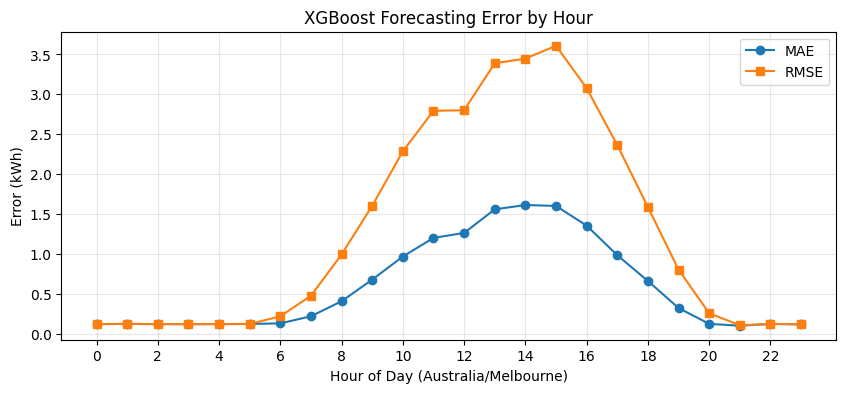

Giờ có MAE cao nhất: 14


In [199]:
hourly = error_df.groupby("Hour").agg(
    MAE=("XGB_AE", "mean"),
    MSE=("XGB_SE", "mean"),
    Samples=("Actual", "size")
)

hourly["RMSE"] = np.sqrt(hourly["MSE"])

display(hourly[["MAE", "RMSE", "Samples"]])

plt.figure(figsize=(10, 4))

plt.plot(
    hourly.index,
    hourly["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    hourly.index,
    hourly["RMSE"],
    marker="s",
    label="RMSE"
)

plt.title("XGBoost Forecasting Error by Hour")
plt.xlabel("Hour of Day (Australia/Melbourne)")
plt.ylabel("Error (kWh)")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print("Giờ có MAE cao nhất:", hourly["MAE"].idxmax())

## 130. Phân tích sai số theo Campus

,Sites,Samples,MAE,RMSE
CampusKey,,,,
3,8,49315,1.394973,3.369773
1,27,185881,0.981518,2.434168
4,1,6766,0.917458,1.622968
2,5,32439,0.573666,1.201100
5,1,6880,0.275579,0.495741


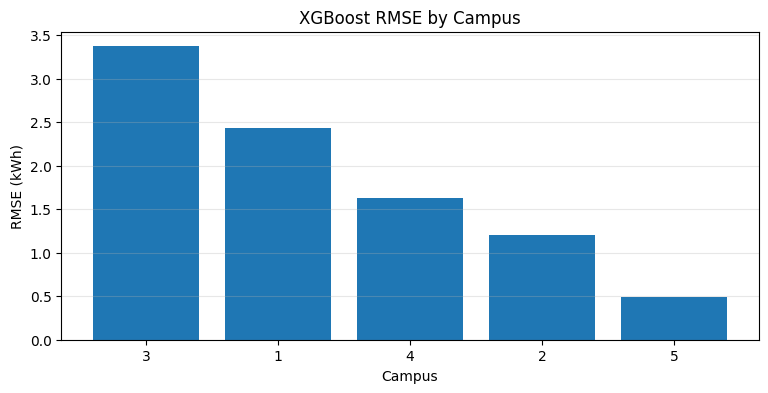

In [200]:
campus_error = error_df.groupby("CampusKey").agg(
    MAE=("XGB_AE", "mean"),
    MSE=("XGB_SE", "mean"),
    Samples=("Actual", "size"),
    Sites=("SiteID", "nunique")
)

campus_error["RMSE"] = np.sqrt(campus_error["MSE"])

campus_error = campus_error.sort_values(
    "RMSE", ascending=False
)

display(
    campus_error[["Sites", "Samples", "MAE", "RMSE"]]
)

plt.figure(figsize=(9, 4))

plt.bar(
    campus_error.index,
    campus_error["RMSE"]
)

plt.title("XGBoost RMSE by Campus")
plt.xlabel("Campus")
plt.ylabel("RMSE (kWh)")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 131. Phân tích sai số theo tháng

,MAE,RMSE,Samples
Month,,,
1,1.035903,2.622686,63947
2,1.037621,2.627429,54902
3,0.949648,2.301288,57798
4,0.896207,2.205664,38507
11,1.022788,3.009002,1706
12,0.987226,2.491615,64421


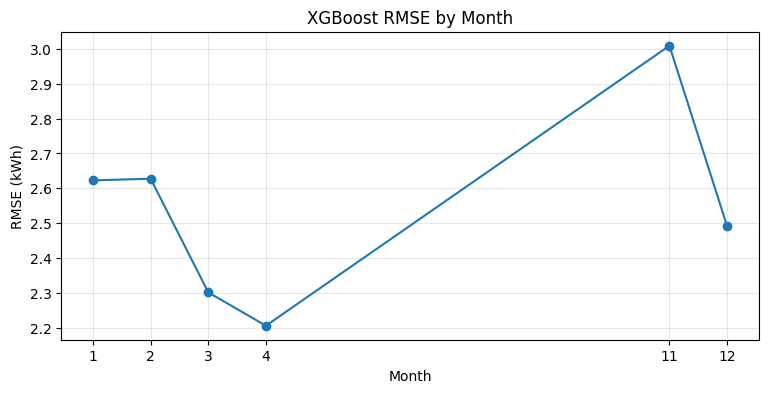

In [201]:
monthly_error = error_df.groupby("Month").agg(
    MAE=("XGB_AE", "mean"),
    MSE=("XGB_SE", "mean"),
    Samples=("Actual", "size")
)

monthly_error["RMSE"] = np.sqrt(
    monthly_error["MSE"]
)

display(
    monthly_error[["MAE", "RMSE", "Samples"]]
)

plt.figure(figsize=(9, 4))

plt.plot(
    monthly_error.index,
    monthly_error["RMSE"],
    marker="o"
)

plt.title("XGBoost RMSE by Month")
plt.xlabel("Month")
plt.ylabel("RMSE (kWh)")
plt.xticks(monthly_error.index)
plt.grid(alpha=0.3)
plt.show()

## 132. Phân tích các trường hợp sai số lớn

,Timestamp,SiteID,Actual,XGBoost,XGB_Error,XGB_AE
462110,2022-01-08 05:00:00+00:00,3_11,4.1875,85.989563,-81.802063,81.802063
160571,2022-02-19 01:45:00+00:00,1_25,3.3125,76.545303,-73.232803,73.232803
463642,2022-01-24 04:00:00+00:00,3_11,19.2500,78.785957,-59.535957,59.535957
458354,2021-11-30 02:00:00+00:00,3_11,25.3750,84.203514,-58.828514,58.828514
159909,2022-02-12 04:15:00+00:00,1_25,14.6875,69.919296,-55.231796,55.231796
458453,2021-12-01 02:45:00+00:00,3_11,90.6250,38.294502,52.330498,52.330498
159525,2022-02-08 04:15:00+00:00,1_25,16.0625,67.917625,-51.855125,51.855125
187303,2022-02-08 04:15:00+00:00,1_27,14.2500,64.797302,-50.547302,50.547302
462111,2022-01-08 05:15:00+00:00,3_11,82.5000,33.313171,49.186829,49.186829
152983,2021-12-02 00:45:00+00:00,1_25,18.8125,67.389526,-48.577026,48.577026


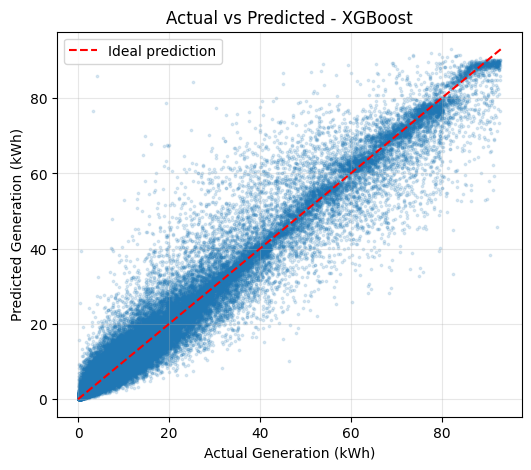

In [202]:
worst_predictions = (
    error_df.sort_values(
        "XGB_AE",
        ascending=False
    )
    .head(20)
)

display(
    worst_predictions[
        [
            "Timestamp",
            "SiteID",
            "Actual",
            "XGBoost",
            "XGB_Error",
            "XGB_AE"
        ]
    ]
)

plt.figure(figsize=(6, 5))

plt.scatter(
    error_df["Actual"],
    error_df["XGBoost"],
    s=3,
    alpha=0.15
)

max_value = max(
    error_df["Actual"].max(),
    error_df["XGBoost"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual Generation (kWh)")
plt.ylabel("Predicted Generation (kWh)")
plt.title("Actual vs Predicted - XGBoost")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 133. So sánh Hybrid với XGBoost

,XGBoost_MAE,Hybrid_MAE,Improvement
Hour,,,
0,0.117782,0.120140,-0.002357
1,0.120414,0.121672,-0.001258
2,0.117347,0.119076,-0.001729
3,0.117416,0.118527,-0.001111
4,0.118037,0.118826,-0.000789
5,0.119559,0.120198,-0.000638
6,0.127061,0.131794,-0.004732
7,0.216123,0.216065,0.000058
8,0.404426,0.401341,0.003086


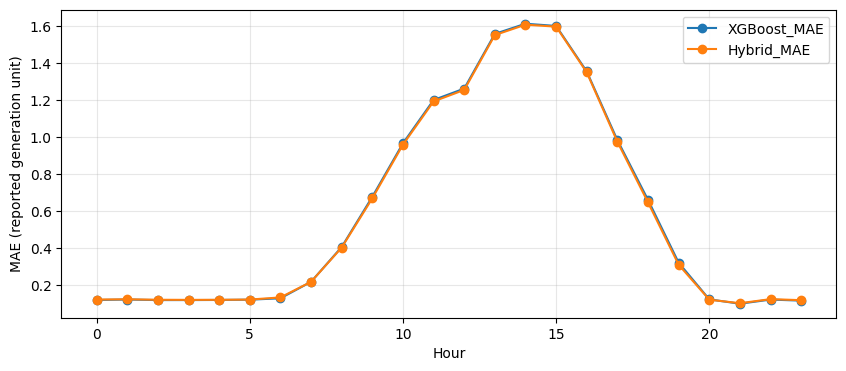

Hybrid AE thấp hơn XGBoost trên 54.21 % số đo thật.


In [203]:
error_df['Hybrid_AE']=(error_df['Actual']-error_df['Hybrid']).abs()
error_df['Improvement']=error_df['XGB_AE']-error_df['Hybrid_AE']
comparison=error_df.groupby('Hour').agg(XGBoost_MAE=('XGB_AE','mean'),Hybrid_MAE=('Hybrid_AE','mean'),Improvement=('Improvement','mean'))
display(comparison)
comparison[['XGBoost_MAE','Hybrid_MAE']].plot(figsize=(10,4),marker='o')
plt.ylabel('MAE (reported generation unit)'); plt.grid(alpha=.3); plt.show()
print('Hybrid AE thấp hơn XGBoost trên',round(100*error_df['Improvement'].gt(0).mean(),2),'% số đo thật.')

In [204]:
from pathlib import Path

A_DIR = Path("/kaggle/working/experiment_A")
A_DIR.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    A_DIR / "baseline_results_A.csv",
    index=False
)

# Lưu các số đo thật được dùng để đánh giá A
test_observed_A = baseline_compare_clean.loc[
    baseline_compare_clean["ObservedValid"],
    ["SiteID", "Timestamp_UTC", "Actual"]
].copy()

test_observed_A.to_csv(
    A_DIR / "test_observed_A.csv",
    index=False
)

print("Đã lưu kết quả A tại:", A_DIR)

Đã lưu kết quả A tại: /kaggle/working/experiment_A
